# Explainable and Fair Heart Disease Prediction: Understanding Bias and Fairness Trade-offs

## UCI Heart Disease Dataset

This notebook investigates sources of gender bias in heart disease prediction using explainability tools, and measures fairness trade-offs across five metrics. Three models are compared (Logistic Regression, Random Forest and XGBoost), explained using SHAP and LIME, and audited for fairness between male and female patients.

## 1. Data Loading and Exploration

In [1]:
# Import libraries for data analysis, visualisation and machine learning

# Pandas for data manipulation and NumPy for numerical operations
import pandas as pd
import numpy as np

# Seaborn and matplotlib for data visualisation
import seaborn as sns
from matplotlib import pyplot as plt

# Display plots inline in the notebook
%matplotlib inline

# Set a clean and consistent style for all plots in the notebook
sns.set_style('white')

# Set consistent font sizes for titles, axis labels and ticks
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Keep the original dtype when filling missing values rather than silently downcasting
pd.set_option('future.no_silent_downcasting', True)

# Fix the random seed so that results are reproducible
random_state = 42

In [2]:
# Load the UCI heart disease dataset from the data folder
df = pd.read_csv('../data/heart_disease_uci.csv')

# List all column names to understand the structure of the dataset
df.columns

Index(['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs',
       'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='object')

The dataset contains the following columns. The descriptions are based on the original UCI documentation, with the column names matching this version of the dataset.

| Column | Description |
|---|---|
| `id` | Unique identifier for each patient |
| `age` | Age of the patient in years |
| `sex` | Sex of the patient (Male / Female) |
| `dataset` | Place of study (the hospital where the data was collected) |
| `cp` | Chest pain type (typical angina, atypical angina, non-anginal, asymptomatic) |
| `trestbps` | Resting blood pressure (in mm Hg on admission to hospital) |
| `chol` | Serum cholesterol in mg/dl |
| `fbs` | Whether fasting blood sugar is greater than 120 mg/dl |
| `restecg` | Resting electrocardiographic results (normal, ST-T abnormality, LV hypertrophy) |
| `thalch` | Maximum heart rate achieved |
| `exang` | Exercise-induced angina (True / False) |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | The slope of the peak exercise ST segment |
| `ca` | Number of major vessels (0-3) coloured by fluoroscopy |
| `thal` | Thalassemia result (normal, fixed defect, reversible defect) |
| `num` | The target attribute (degree of heart disease, 0-4) |

In [3]:
# Check the number of rows and columns in the dataset
print('The dataset has {} rows and {} columns'.format(df.shape[0], df.shape[1]))

# Display the first five rows to see what the data looks like
df.head()

The dataset has 920 rows and 16 columns


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [4]:
# Display data types, non-null counts and memory usage for each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [5]:
# Summary statistics to check the range, spread and any clinically impossible values such as a reading of zero
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [6]:
# Count the hidden missing values stored as 0 in chol and trestbps, which are clinically impossible
print('Number of patients with cholesterol = 0: {}'.format((df['chol'] == 0).sum()))
print('Number of patients with resting blood pressure = 0: {}'.format((df['trestbps'] == 0).sum()))

Number of patients with cholesterol = 0: 172
Number of patients with resting blood pressure = 0: 1


The `describe()` output revealed that `chol` and `trestbps` have a minimum of 0, which is clinically impossible because cholesterol and blood pressure can never be zero in a living patient. These are hidden missing values stored as 0 rather than NaN: 172 patients have a cholesterol of 0 (18.70% of the data) and 1 patient has a resting blood pressure of 0. During preprocessing these zeros will be treated as missing values rather than real measurements.

### Check data quality

Missing values and duplicated rows are checked to identify any data quality issues
before analysis.

In [7]:
# Check for missing values in each column, sorted from highest to lowest
df.isnull().sum().sort_values(ascending=False)

ca          611
thal        486
slope       309
fbs          90
oldpeak      62
trestbps     59
thalch       55
exang        55
chol         30
restecg       2
id            0
age           0
sex           0
dataset       0
cp            0
num           0
dtype: int64

In [8]:
# Check for duplicated rows as part of the data quality checks
print('Number of duplicated rows: {}'.format(df.duplicated().sum()))

Number of duplicated rows: 0


The columns `ca`, `thal` and `slope` have a very large amount of missing data (66.41%, 52.83% and 33.59% respectively), so imputing them would introduce too much artificial data. These columns are candidates for removal during preprocessing. Importantly, the target `num` and the `sex` column have no missing values at all, which is good for a gender-based fairness analysis.

In [9]:
# Drop the id column as it is just a patient identifier with no predictive value
print('id has no analytic value: {} unique values, one per patient ... so I can drop it'
      .format(df['id'].nunique()))
df = df.drop(['id'], axis=1)

id has no analytic value: 920 unique values, one per patient ... so I can drop it


## 2. Exploratory Data Analysis

The target variable, numerical features and categorical features are analysed to understand patterns in the data and to see which features might be useful for predicting heart disease.

In [10]:
# Save a backup copy of the dataframe before exploratory analysis and any transformations, so the original cleaned data can be restored if needed.
df_original = df.copy()

In [11]:
# The target 'num' ranges from 0 to 4, where 0 means no disease and 1-4 are increasing severity. For this study we convert it into a binary target: 0 = no heart disease, 1 = heart disease present.
df['target'] = (df['num'] > 0).astype(int)

# Check the distribution of the new binary target as counts and as proportions
print('Counts for the target are:\n{}'.format(df['target'].value_counts()))
print('\nProportions for the target are:\n{}'.format(df['target'].value_counts(normalize=True)))

Counts for the target are:
target
1    509
0    411
Name: count, dtype: int64

Proportions for the target are:
target
1    0.553261
0    0.446739
Name: proportion, dtype: float64


The binary target is reasonably balanced, with 55.33% of patients having heart disease and 44.67% not. Unlike a heavily imbalanced dataset, this means class imbalance is not a major problem in itself. The more important question for this study is how this rate differs between male and female patients, which is examined next.

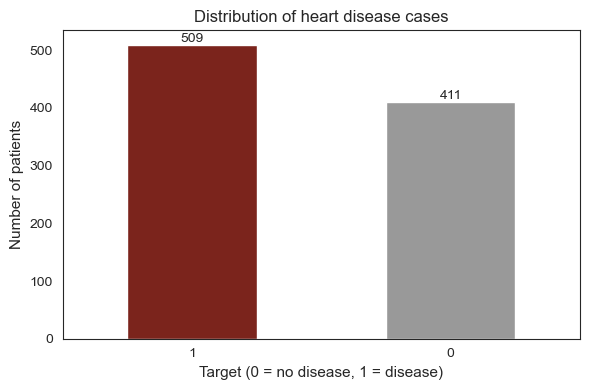

In [12]:
# Visualise the distribution of the binary target with a bar chart
ax = df['target'].value_counts().plot(kind='bar', figsize=(6, 4), color=['#7b241c', '#999999'])
plt.title('Distribution of heart disease cases')
plt.xlabel('Target (0 = no disease, 1 = disease)')
plt.ylabel('Number of patients')
plt.xticks(rotation=0)

# Add the count on top of each bar for readability
for i, count in enumerate(df['target'].value_counts()):
    ax.text(i, count + 5, str(count), ha='center')
    
plt.tight_layout()
plt.show()

### Gender base rates — the core of the fairness analysis

The rate of heart disease is compared between male and female patients. A large difference in base rates between the two groups is what makes fairness trade-offs unavoidable, so this is the central observation for the rest of the analysis.

In [13]:
# Compare the heart disease rate between male and female patients
# The crosstab shows counts, and normalising by row gives the rate within each sex
gender_counts = pd.crosstab(df['sex'], df['target'])
print('Counts of disease by sex:\n{}'.format(gender_counts))

gender_rates = pd.crosstab(df['sex'], df['target'], normalize='index')
print('\nProportion of disease within each sex:\n{}'.format(gender_rates))

Counts of disease by sex:
target    0    1
sex             
Female  144   50
Male    267  459

Proportion of disease within each sex:
target         0         1
sex                       
Female  0.742268  0.257732
Male    0.367769  0.632231


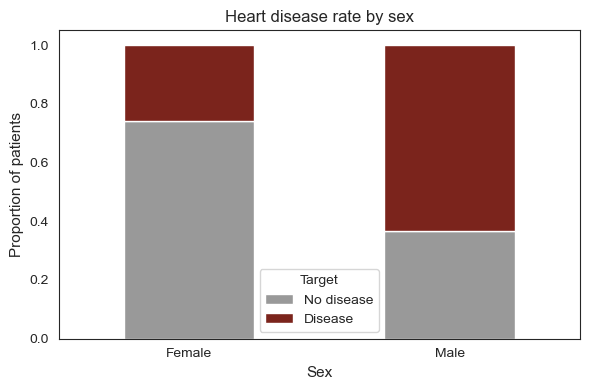

In [14]:
# Visualise the disease rate within each sex as a stacked bar chart
# Each bar is one sex, split into the proportion with and without disease
gender_rates.plot(kind='bar', stacked=True, figsize=(6, 4), color=['#999999', '#7b241c'])
plt.title('Heart disease rate by sex')
plt.xlabel('Sex')
plt.ylabel('Proportion of patients')
plt.xticks(rotation=0)
plt.legend(['No disease', 'Disease'], title='Target')
plt.tight_layout()
plt.show()

There is a large difference in the heart disease rate between the two sexes. In this dataset 63.22% of male patients have heart disease, compared with only 25.77% of female patients, which is a gap of 37.45 percentage points. This gap comes from the data itself rather than from any modelling choice.

This base rate difference is the central reason why fairness trade-offs are difficult to avoid. When two groups have very different base rates, it becomes mathematically impossible to satisfy several fairness criteria at the same time, so improving one fairness measure tends to worsen another. This dataset is therefore expected to show a strong trade-off, which is examined in the fairness analysis later on.

### Is the sex difference also present within hospitals?

The dataset combines four hospitals with different patient populations, so the overall sex gap could partly reflect which hospital patients came from. To check this, the number of patients and the heart disease rate are compared between male and female patients within each hospital. If men still have a higher rate than women inside the same hospital, the sex gap holds within hospitals and is not only an artefact of the hospital mix.

Number of patients by hospital and sex:
sex            Female  Male
dataset                    
Cleveland          97   207
Hungary            81   212
Switzerland        10   113
VA Long Beach       6   194


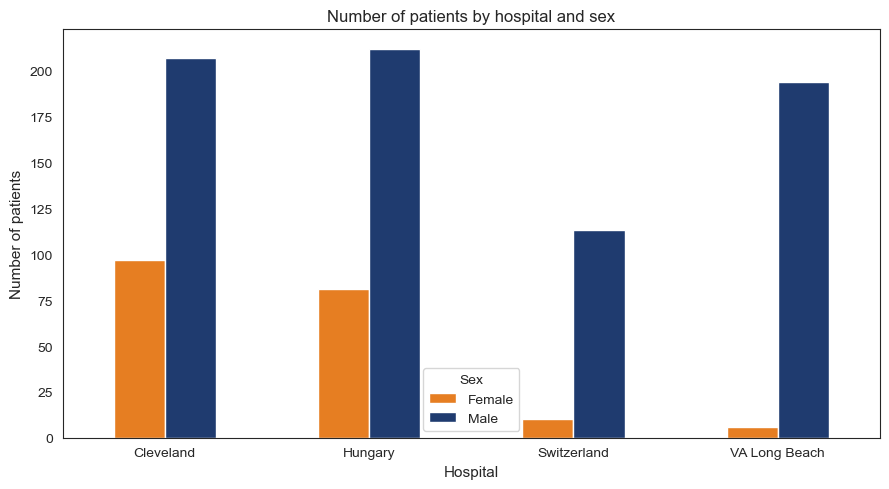

In [15]:
# Show the actual number of male and female patients in each hospital
# This reveals how many patients each rate is based on, so small groups are not over-interpreted
sex_hospital_count = df.groupby(['dataset', 'sex']).size().unstack()
print('Number of patients by hospital and sex:\n{}'.format(sex_hospital_count))

sex_hospital_count.plot(kind='bar', figsize=(9, 5), color=['#e67e22', '#1f3b6f'])
plt.title('Number of patients by hospital and sex')
plt.xlabel('Hospital')
plt.ylabel('Number of patients')
plt.xticks(rotation=0)
plt.legend(title='Sex')
plt.tight_layout()
plt.show()

The number of female patients varies a lot between hospitals. Cleveland and Hungary have a reasonable number of women (97 and 81), but Switzerland has only 10 female patients and VA Long Beach only 6. This matters for the next chart: any disease rate for women in Switzerland or VA Long Beach is based on very few patients and should not be read as reliable.

Heart disease rate by hospital and sex:
sex              Female      Male
dataset                          
Cleveland      0.257732  0.550725
Hungary        0.148148  0.443396
Switzerland    1.000000  0.929204
VA Long Beach  0.500000  0.752577


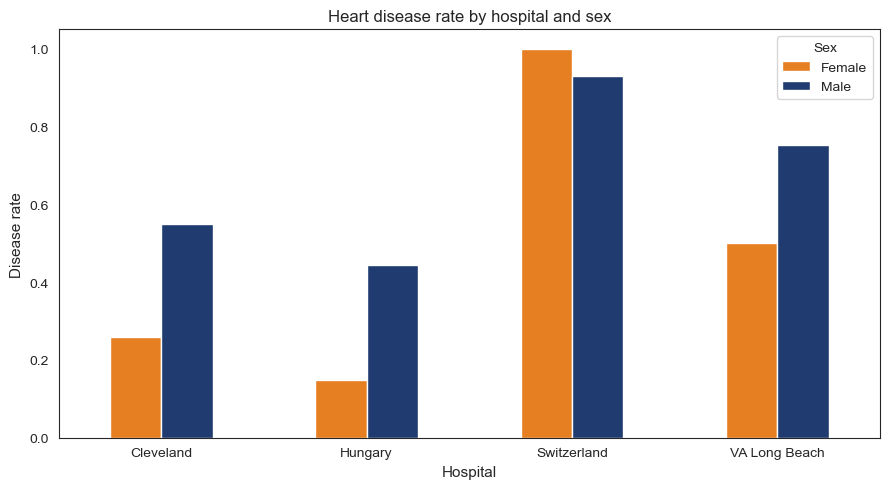

In [16]:
# Compare the heart disease rate for men and women within each hospital
# If men have a higher rate than women inside the same hospital, the sex gap holds within hospitals and is not only due to which hospital they came from
sex_hospital_rate = df.groupby(['dataset', 'sex'])['target'].mean().unstack()
print('Heart disease rate by hospital and sex:\n{}'.format(sex_hospital_rate))

sex_hospital_rate.plot(kind='bar', figsize=(9, 5), color=['#e67e22', '#1f3b6f'])
plt.title('Heart disease rate by hospital and sex')
plt.xlabel('Hospital')
plt.ylabel('Disease rate')
plt.xticks(rotation=0)
plt.legend(title='Sex')
plt.tight_layout()
plt.show()

Within the hospitals that have enough women, men clearly have a higher disease rate than women: Cleveland 55.07% versus 25.77% and Hungary 44.34% versus 14.81%. The recorded sex gap therefore persists within Cleveland and Hungary and is not only caused by the hospital mix, since it holds inside the same hospital. Switzerland and VA Long Beach look different (women at 100.00% and 50.00%), but as noted above these rates come from only 10 and 6 women respectively, so they are not reliable. Overall, where the sample is large enough the sex gap persists within hospitals, which supports treating sex as a genuine factor in the fairness analysis.

### Is the sex difference explained by age?

Age is a strong risk factor for heart disease, so a difference in disease rates between the sexes could partly reflect an age difference between male and female patients rather than sex itself. To check this, the age distribution is compared between the two sexes. If men and women have similar ages, then age cannot explain the gap in disease rates, which strengthens the case that the gap is not an age artefact.

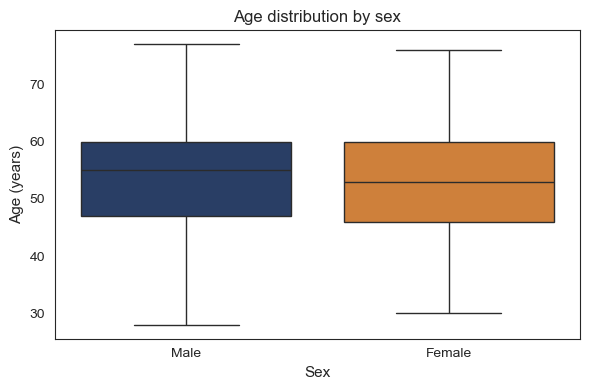

Mean age by sex:
sex
Female    52.474227
Male      53.787879
Name: age, dtype: float64


In [17]:
# Compare the age distribution between male and female patients
# If the two sexes have similar ages, then age cannot explain the difference in their disease rates
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='sex', y='age', hue='sex', palette=['#1f3b6f', '#e67e22'], legend=False)
plt.title('Age distribution by sex')
plt.xlabel('Sex')
plt.ylabel('Age (years)')
plt.tight_layout()
plt.show()

# Print the mean age for each sex to support the plot
print('Mean age by sex:\n{}'.format(df.groupby('sex')['age'].mean()))

The two sexes have very similar ages: the mean age is 52.47 years for female patients and 53.79 years for male patients, a difference of only about one year. Because age is so similar across the sexes, the large gap in disease rates (63.22% for men versus 25.77% for women) is not explained by an age difference between them. Together with the earlier hospital check, this means the sex gap remains after accounting for both hospital and age, which is why sex is carried into the fairness analysis rather than set aside.

### Numerical features and heart disease

The five numerical features (age, resting blood pressure, cholesterol, maximum heart rate and ST depression) are examined next. Their distributions are checked first, then they are compared between the sexes and between patients with and without heart disease, and finally their correlations with the target are summarised in a heatmap. This shows which numerical measurements are most strongly related to heart disease.

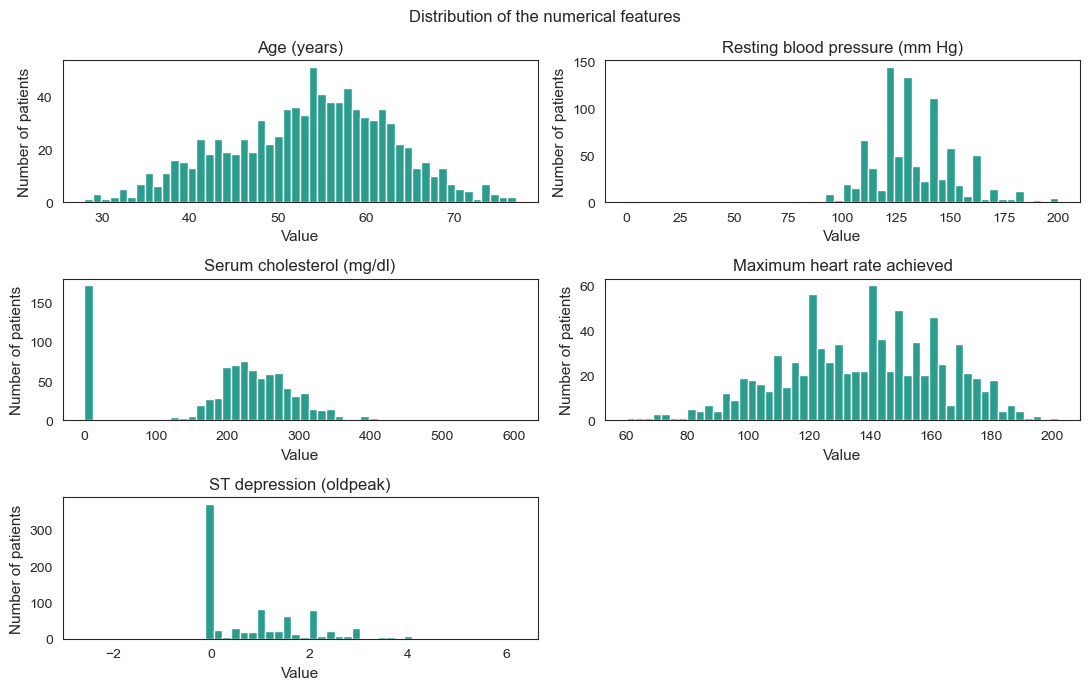

In [18]:
# Look at the distribution of the main numerical features with histograms
# The x-axis is the value of each feature and the y-axis is the number of patients in that range
numerical_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
readable_names = ['Age (years)', 'Resting blood pressure (mm Hg)', 'Serum cholesterol (mg/dl)', 'Maximum heart rate achieved', 'ST depression (oldpeak)']

df_plot = df[numerical_cols].copy()
df_plot.columns = readable_names

axes = df_plot.hist(figsize=(11, 7), color='#2a9d8f', edgecolor='white', grid=False, bins=50)
# Label both axes on each subplot so it is clear what they show
for row in axes:
    for ax in row:
        ax.set_xlabel('Value')
        ax.set_ylabel('Number of patients')
        
plt.suptitle('Distribution of the numerical features')
plt.tight_layout()
plt.show()

The histograms confirm the earlier finding visually: the cholesterol plot shows a clear spike at zero, separate from the main distribution around 200–300 mg/dl, which reflects the 172 patients whose cholesterol was recorded as 0. The other features all fall within clinically plausible ranges with no extreme outliers.

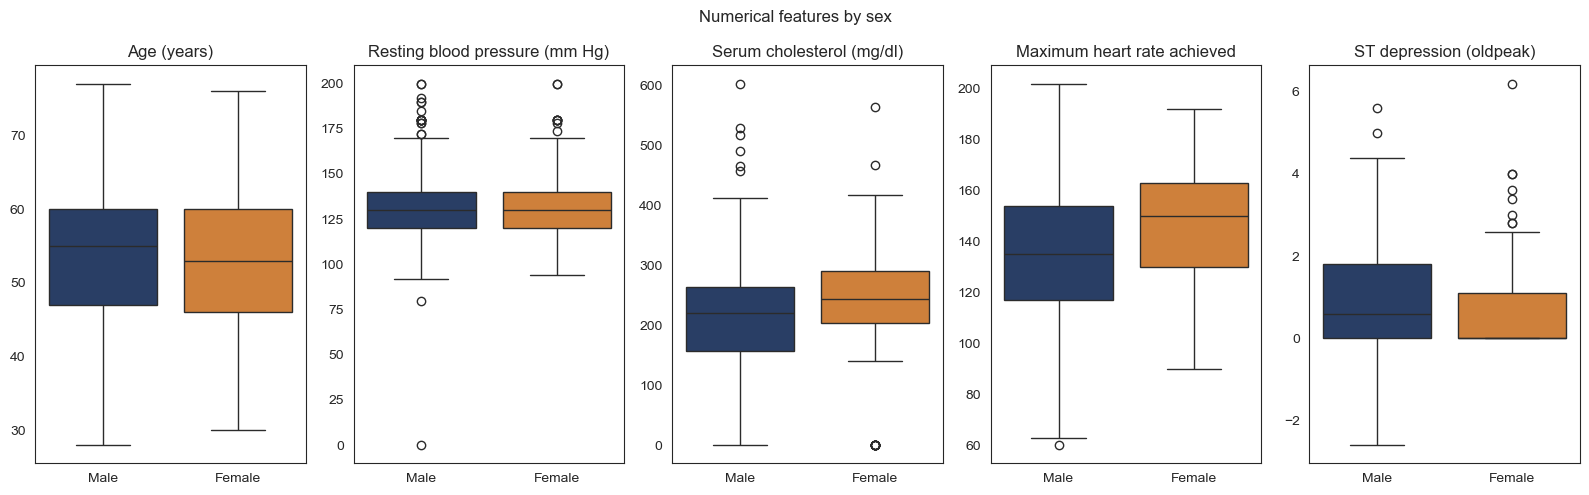

In [19]:
# Compare the numerical features between male and female patients with boxplots
# This shows whether the two sexes differ in their clinical measurements
numerical_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
feature_labels = {'age': 'Age (years)', 'trestbps': 'Resting blood pressure (mm Hg)', 'chol': 'Serum cholesterol (mg/dl)', 'thalch': 'Maximum heart rate achieved', 'oldpeak': 'ST depression (oldpeak)'}

fig, axes = plt.subplots(1, 5, figsize=(16, 5))
for i, col in enumerate(numerical_cols):
    sns.boxplot(data=df, x='sex', y=col, hue='sex', ax=axes[i], palette=['#1f3b6f', '#e67e22'], legend=False)
    axes[i].set_title(feature_labels[col])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

plt.suptitle('Numerical features by sex')
plt.tight_layout()
plt.show()

The boxplots show that the two sexes differ not only in their disease rate but also in some clinical measurements. Female patients tend to have slightly higher cholesterol and a higher maximum heart rate, while male patients tend to have higher ST depression (oldpeak). These differences are clinically plausible and matter for fairness, because if a feature behaves differently across the sexes, a model may rely on it differently for male and female patients. This is an early sign of where gender differences could enter the model, and it is examined more directly later with gender-stratified SHAP.

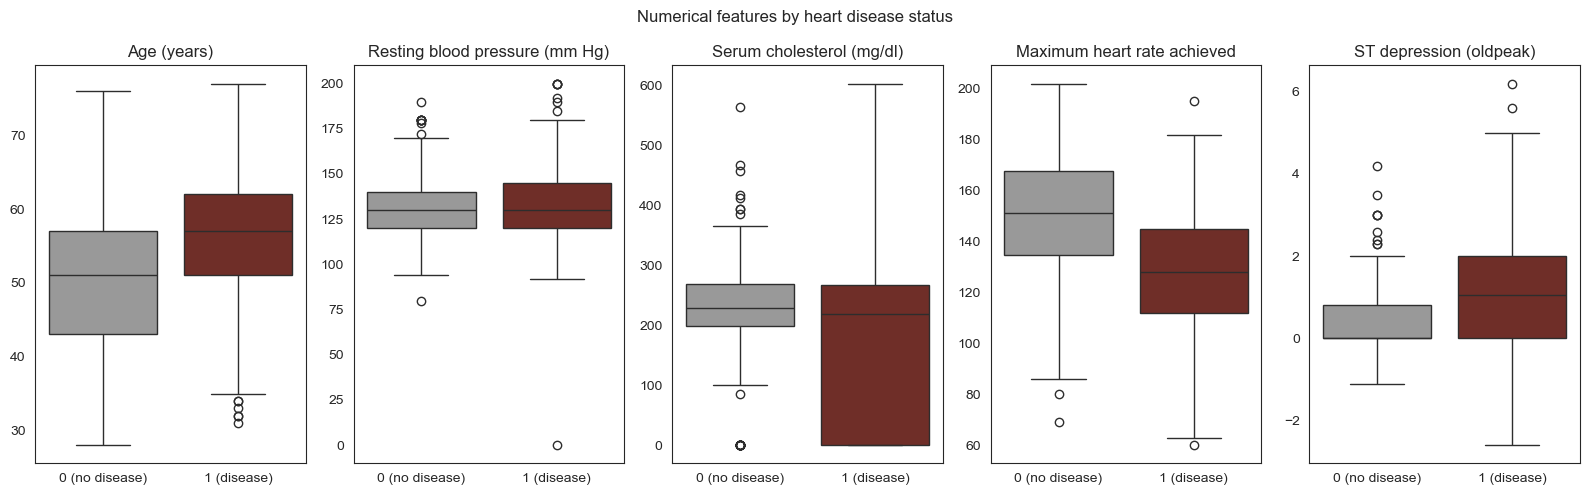

In [20]:
# Compare the numerical features between patients with and without heart disease with boxplots
# This shows which measurements separate the two groups and are likely to be useful predictors
numerical_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
feature_labels = {'age': 'Age (years)', 'trestbps': 'Resting blood pressure (mm Hg)', 'chol': 'Serum cholesterol (mg/dl)', 'thalch': 'Maximum heart rate achieved', 'oldpeak': 'ST depression (oldpeak)'}

fig, axes = plt.subplots(1, 5, figsize=(16, 5))
for i, col in enumerate(numerical_cols):
    sns.boxplot(data=df, x='target', y=col, hue='target', ax=axes[i], palette=['#999999', '#7b241c'], legend=False)
    axes[i].set_title(feature_labels[col])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['0 (no disease)', '1 (disease)'])
    
plt.suptitle('Numerical features by heart disease status')
plt.tight_layout()
plt.show()

The boxplots show which measurements separate patients with and without heart disease. The clearest differences are in maximum heart rate and ST depression (oldpeak): patients with heart disease tend to reach a lower maximum heart rate and have higher ST depression, which matches the correlation heatmap where these two features had the strongest relationship with the target. Age is slightly higher for patients with disease, while resting blood pressure and cholesterol separate the groups much less (the cholesterol picture is also affected by the recorded zero values). This visual check agrees with the correlation analysis and gives an early indication of which features the models are likely to rely on, which can later be compared against the SHAP results.

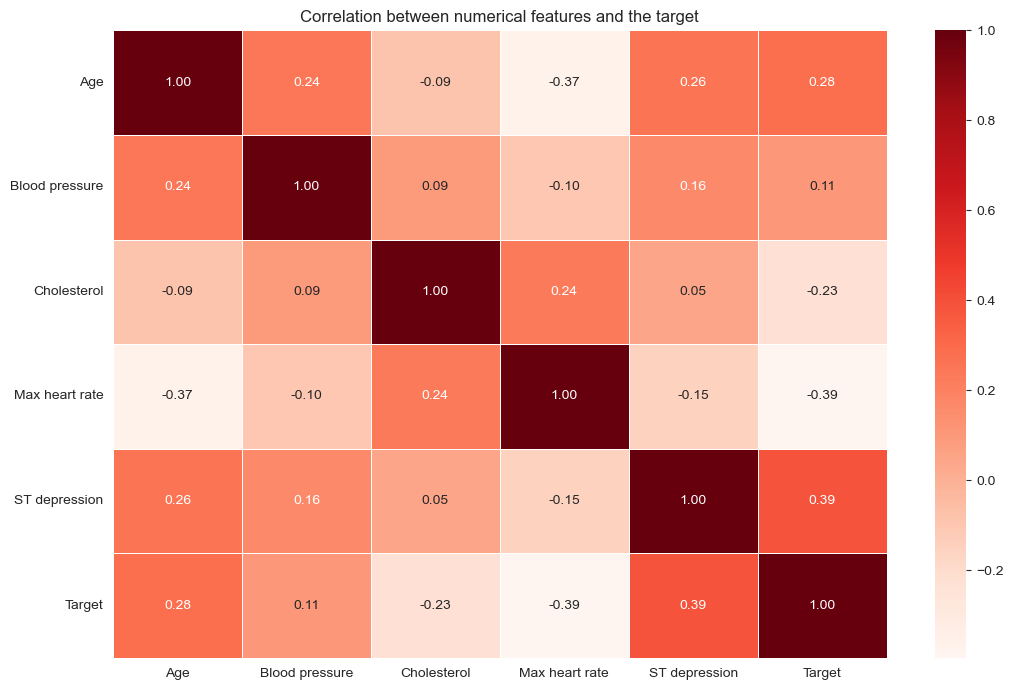

Correlation of each feature with the target:
Target            1.000000
ST depression     0.385528
Age               0.282700
Blood pressure    0.106233
Cholesterol      -0.230583
Max heart rate   -0.394503
Name: Target, dtype: float64

Correlation between features:
                     Age  Blood pressure  Cholesterol  Max heart rate  \
Age             1.000000        0.244253    -0.086234       -0.365778   
Blood pressure  0.244253        1.000000     0.092853       -0.104899   
Cholesterol    -0.086234        0.092853     1.000000        0.236121   
Max heart rate -0.365778       -0.104899     0.236121        1.000000   
ST depression   0.258243        0.161908     0.047734       -0.151174   

                ST depression  
Age                  0.258243  
Blood pressure       0.161908  
Cholesterol          0.047734  
Max heart rate      -0.151174  
ST depression        1.000000  


In [21]:
# Look at the correlation between the numerical features and the target
# A heatmap makes it easy to see which features are related to heart disease
numerical_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
corr = df[numerical_cols + ['target']].corr()

# Use short readable labels so the heatmap stays clear
corr_labels = ['Age', 'Blood pressure', 'Cholesterol', 'Max heart rate', 'ST depression', 'Target']
corr.index = corr_labels
corr.columns = corr_labels

plt.figure(figsize=(11, 7))
sns.heatmap(corr, annot=True, cmap='Reds', fmt='.2f', linewidths=0.5)
plt.title('Correlation between numerical features and the target')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print the correlation of each feature with the target, sorted, to support the heatmap
print('Correlation of each feature with the target:\n{}'.format(corr['Target'].sort_values(ascending=False)))

# Print the correlations between the features (excluding the target) to check for multicollinearity
corr_features = corr.drop('Target', axis=1).drop('Target', axis=0)
print('\nCorrelation between features:\n{}'.format(corr_features))

The correlation heatmap shows that ST depression (oldpeak) has the strongest positive correlation with the target (0.39), while maximum heart rate has the strongest negative correlation (-0.39): patients who reach a higher heart rate are less likely to have heart disease. Age is moderately correlated (0.28). Cholesterol shows a weak negative correlation (-0.23), which is unexpected since cholesterol is normally a risk factor; this is most likely caused by the 172 patients whose cholesterol was recorded as 0, and it should improve once these values are treated as missing during preprocessing. No pair of features exceeds a correlation of 0.85, so there is no multicollinearity problem and no feature needs to be removed for that reason.

### Categorical features and heart disease

The four categorical clinical features (chest pain type, fasting blood sugar, resting ECG and exercise-induced angina) are examined next. They are first compared between male and female patients to see whether the categories are distributed differently by sex, and then the disease rate within each category is calculated to see which categories are associated with a much higher or lower chance of heart disease. This mirrors the analysis of the numerical features above and gives an early indication both of where gender differences could enter the model and of which categorical features are likely to be useful predictors.

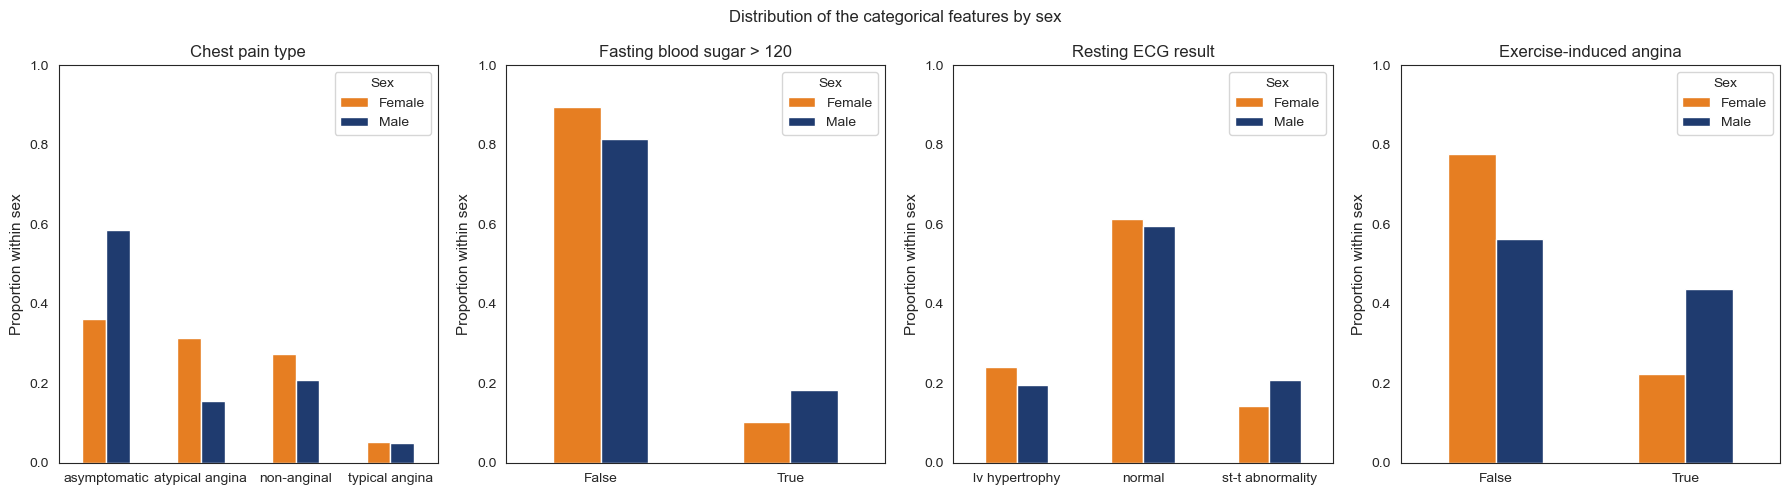

Proportion of cp within each sex:
sex                Female      Male
cp                                 
asymptomatic     0.360825  0.586777
atypical angina  0.314433  0.155647
non-anginal      0.273196  0.207989
typical angina   0.051546  0.049587

Proportion of fbs within each sex:
sex      Female      Male
fbs                      
False  0.896175  0.816074
True   0.103825  0.183926

Proportion of restecg within each sex:
sex                 Female      Male
restecg                             
lv hypertrophy    0.242268  0.194751
normal            0.613402  0.596685
st-t abnormality  0.144330  0.208564

Proportion of exang within each sex:
sex      Female     Male
exang                   
False  0.776042  0.56315
True   0.223958  0.43685



In [22]:
# Compare the categorical features between male and female patients
# For each feature the proportion in each category is calculated within each sex, so the bars show how the distribution differs between men and women
categorical_cols = ['cp', 'fbs', 'restecg', 'exang']
categorical_labels = {'cp': 'Chest pain type', 'fbs': 'Fasting blood sugar > 120', 'restecg': 'Resting ECG result', 'exang': 'Exercise-induced angina'}
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, col in enumerate(categorical_cols):

    # The proportion of each category within each sex, so the two sexes can be compared directly
    sex_distribution = pd.crosstab(df[col], df['sex'], normalize='columns')
    sex_distribution.plot(kind='bar', ax=axes[i], color=['#e67e22', '#1f3b6f'])
    axes[i].set_title(categorical_labels[col])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Proportion within sex')
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(title='Sex')

plt.suptitle('Distribution of the categorical features by sex')
plt.tight_layout()
plt.show()

# Print the exact proportion of each category within each sex to support the charts
for col in categorical_cols:
    print('Proportion of {} within each sex:\n{}\n'.format(col, pd.crosstab(df[col], df['sex'], normalize='columns')))

The categorical features are distributed quite differently between the sexes, especially chest pain type. Among male patients 58.68% have asymptomatic chest pain, compared with only 36.08% of female patients, while atypical angina is about twice as common in women (31.44% versus 15.56%). Exercise-induced angina is also far more common in men (43.69% versus 22.40%), and fasting blood sugar above 120 is somewhat higher in men (18.39% versus 10.38%). Resting ECG is more similar across the sexes. These differences show that the categorical features carry gender information as well, which matters because a model could rely on them differently for male and female patients. The next chart looks at how these same categories relate to heart disease itself.

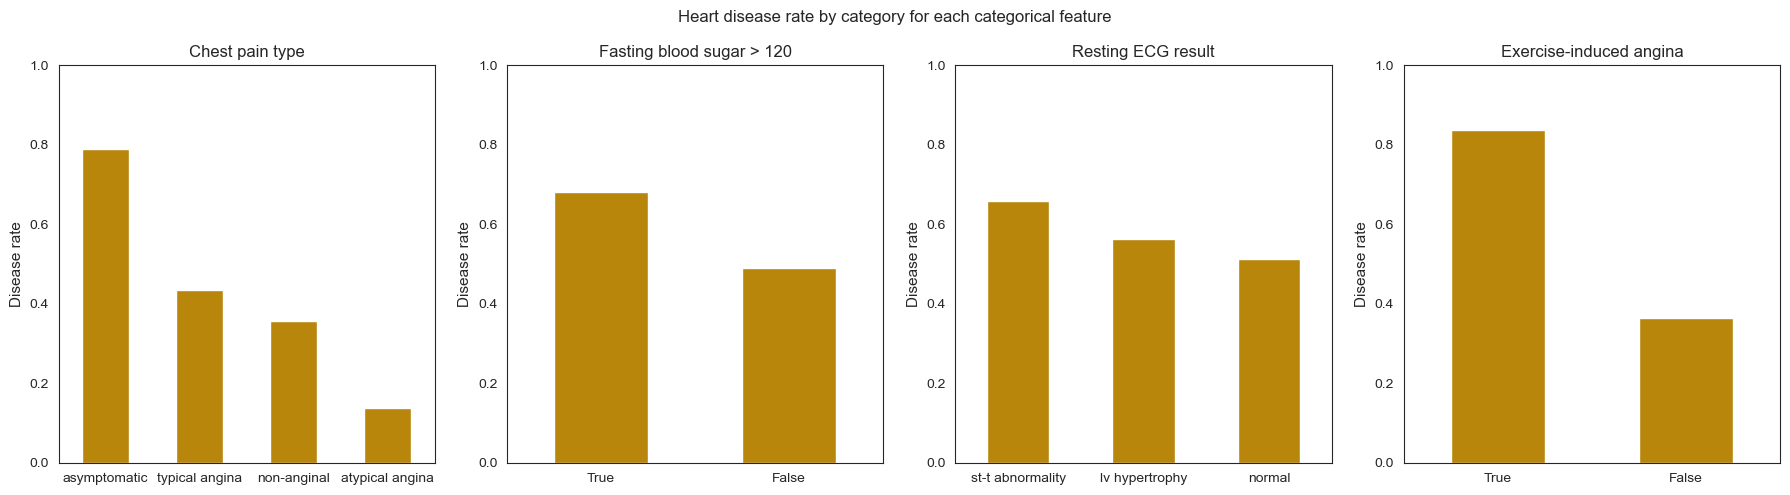

Disease rate by cp:
cp
asymptomatic       0.790323
typical angina     0.434783
non-anginal        0.357843
atypical angina    0.137931
Name: target, dtype: float64

Disease rate by fbs:
fbs
True     0.681159
False    0.489884
Name: target, dtype: float64

Disease rate by restecg:
restecg
st-t abnormality    0.659218
lv hypertrophy      0.563830
normal              0.513612
Name: target, dtype: float64

Disease rate by exang:
exang
True     0.836795
False    0.363636
Name: target, dtype: float64



In [23]:
# Look at the four categorical features and the disease rate within each category
# This shows whether some categories are linked to a much higher chance of heart disease
categorical_cols = ['cp', 'fbs', 'restecg', 'exang']

# Readable titles for each categorical feature
categorical_labels = {'cp': 'Chest pain type', 'fbs': 'Fasting blood sugar > 120', 'restecg': 'Resting ECG result', 'exang': 'Exercise-induced angina'}
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, col in enumerate(categorical_cols):

    # The disease rate within each category, sorted so the highest-risk category is first
    disease_rate = df.groupby(col)['target'].mean().sort_values(ascending=False)
    disease_rate.plot(kind='bar', ax=axes[i], color='#b8860b')
    axes[i].set_title(categorical_labels[col])
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Disease rate')
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis='x', rotation=0)

plt.suptitle('Heart disease rate by category for each categorical feature')
plt.tight_layout()
plt.show()

# Print the exact disease rate within each category to support the charts
for col in categorical_cols:
    print('Disease rate by {}:\n{}\n'.format(col, df.groupby(col)['target'].mean().sort_values(ascending=False)))

The categorical features show clear differences in disease rate between their categories. Chest pain type is the most striking: patients with asymptomatic chest pain have a disease rate of 79.03%, far higher than those with atypical angina at 13.79%. Exercise-induced angina is also a strong signal, with a disease rate of 83.68% when it is present compared with 36.36% when it is absent. Fasting blood sugar above 120 (68.12% versus 48.99%) and an abnormal resting ECG (65.92% for ST-T abnormality versus 51.36% for normal) show smaller but consistent differences. These categorical features therefore look useful for prediction, and the strong patterns in chest pain type and exercise-induced angina can later be compared against the SHAP results to see whether the models rely on the same features.

### Missing data by sex

The columns `ca`, `thal` and `slope` have a lot of missing data and are candidates for removal. Before removing them, the missingness is checked by sex, because if data is missing more often for one sex this is itself a possible source of bias (for example if female patients were tested less often).

In [24]:
# Check the proportion of missing values for ca, thal and slope within each sex
# This shows whether the missing data is balanced between male and female patients
missing_cols = ['ca', 'thal', 'slope']

for col in missing_cols:
    # Create a temporary column marking whether the value is missing, then average it by sex
    df['is_missing'] = df[col].isnull()
    missing_by_sex = df.groupby('sex')['is_missing'].mean()
    print('Proportion of missing {} by sex:\n{}\n'.format(col, missing_by_sex))

# Remove the temporary helper column
df = df.drop(['is_missing'], axis=1)

Proportion of missing ca by sex:
sex
Female    0.500000
Male      0.707989
Name: is_missing, dtype: float64

Proportion of missing thal by sex:
sex
Female    0.427835
Male      0.555096
Name: is_missing, dtype: float64

Proportion of missing slope by sex:
sex
Female    0.314433
Male      0.341598
Name: is_missing, dtype: float64



The missing data is not perfectly balanced between the sexes, but the imbalance is in the opposite direction to what might be expected: ca and thal are missing more often for male patients (70.80% versus 50.00% for ca, 55.51% versus 42.78% for thal) rather than for female patients, while slope is missing at a similar rate for both (34.16% versus 31.44%). This means the missingness is unlikely to disadvantage female patients specifically. Because ca and thal are missing for more than half of all patients, they will be removed during preprocessing; slope, with about a third missing, will be reconsidered at that stage.

## 3. Data Preprocessing

Before modelling, the data is cleaned and prepared. The hidden missing values found during exploration are converted to proper missing values, the columns with too much missing data are removed, the categorical features are encoded as numbers, and the remaining missing values are imputed. The data is then split into training and test sets before any resampling, so that information from the test set never leaks into training.

In [25]:
# Convert the hidden missing values to NaN
# Cholesterol and blood pressure of 0 are clinically impossible, so they are really missing values stored as 0
df['chol'] = df['chol'].replace(0, np.nan)
df['trestbps'] = df['trestbps'].replace(0, np.nan)

# Check the updated missing values for all columns after the zeros have been converted
df.isnull().sum().sort_values(ascending=False)

ca          611
thal        486
slope       309
chol        202
fbs          90
oldpeak      62
trestbps     60
thalch       55
exang        55
restecg       2
age           0
sex           0
dataset       0
cp            0
num           0
target        0
dtype: int64

### Why these columns are missing — missingness by hospital

Before deciding what to do with `ca`, `thal` and `slope`, the missingness is checked by hospital. The dataset combines four hospitals, and if the gaps come from certain hospitals not recording these tests rather than from the patients, that affects how the missing data should be handled.

In [26]:
# Check the proportion of missing values for ca, thal and slope within each hospital
# The dataset combines four hospitals, so this shows whether the missingness is concentrated in particular sites
missing_cols = ['ca', 'thal', 'slope']

for col in missing_cols:
    # Create a temporary column marking whether the value is missing, then average it by hospital
    df['is_missing'] = df[col].isnull()
    missing_by_hospital = df.groupby('dataset')['is_missing'].mean()
    print('Proportion of missing {} by hospital:\n{}\n'.format(col, missing_by_hospital))

# Remove the temporary helper column
df = df.drop(['is_missing'], axis=1)

Proportion of missing ca by hospital:
dataset
Cleveland        0.016447
Hungary          0.989761
Switzerland      0.959350
VA Long Beach    0.990000
Name: is_missing, dtype: float64

Proportion of missing thal by hospital:
dataset
Cleveland        0.009868
Hungary          0.904437
Switzerland      0.422764
VA Long Beach    0.830000
Name: is_missing, dtype: float64

Proportion of missing slope by hospital:
dataset
Cleveland        0.003289
Hungary          0.645051
Switzerland      0.138211
VA Long Beach    0.510000
Name: is_missing, dtype: float64



The missingness is almost entirely driven by the hospital, not the patients. At the Cleveland site these tests are nearly always recorded (only 1.64% of `ca`, 0.99% of `thal` and 0.33% of `slope` are missing), but the other three hospitals mostly did not record them: `ca` is missing for 98.98% of Hungary, 99.00% of VA Long Beach and 95.94% of Switzerland patients, with a similar pattern for `thal` and `slope`. Because the gaps come from data collection rather than from the patients, imputing this much missing data would replace real measurements with a very large amount of artificial values and distort the distributions. All three columns are therefore dropped rather than imputed. This includes `slope`: although it is the least incomplete of the three (33.59% missing overall), its missingness follows the same hospital-driven pattern, so it is removed for consistency rather than imputed from a single hospital.

In [27]:
# Drop the three columns with too much missing data
# As shown above, ca, thal and slope are missing for most patients outside Cleveland, so they are removed rather than imputed
df = df.drop(['ca', 'thal', 'slope'], axis=1)

# Confirm the columns have been removed
print('Columns after dropping high-missing features:\n{}'.format(df.columns.tolist()))

Columns after dropping high-missing features:
['age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'num', 'target']


The remaining missing values are filled in rather than dropped, so that no patients are lost. After dropping the three high-missing columns, the remaining gaps are moderate: cholesterol has 202 missing values (21.96%, including the zeros just converted), fasting blood sugar 90 (9.78%), oldpeak 62 (6.74%), resting blood pressure 60 (6.52%), maximum heart rate and exercise-induced angina 55 each (5.98%), and resting ECG only 2 (0.22%). The categorical columns (`fbs`, `restecg`, `exang`) are filled with their most frequent value (the mode). The numerical columns (`chol`, `trestbps`, `thalch`, `oldpeak`) are filled with their median rather than the mean, because these clinical measurements are skewed and contain outliers (for example a cholesterol value of 603), and the median is more robust to such extreme values than the mean.

In [28]:
# Fill the categorical columns with their most frequent value (the mode)
df['fbs'] = df['fbs'].fillna(df['fbs'].mode()[0])
df['restecg'] = df['restecg'].fillna(df['restecg'].mode()[0])
df['exang'] = df['exang'].fillna(df['exang'].mode()[0])

# Fill the numerical columns with their median, which is robust to skew and outliers
df['chol'] = df['chol'].fillna(df['chol'].median())
df['trestbps'] = df['trestbps'].fillna(df['trestbps'].median())
df['thalch'] = df['thalch'].fillna(df['thalch'].median())
df['oldpeak'] = df['oldpeak'].fillna(df['oldpeak'].median())

# Confirm there are no missing values left
print('Missing values after imputation:\n{}'.format(df.isnull().sum().sort_values(ascending=False)))

Missing values after imputation:
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
num         0
target      0
dtype: int64


### Re-check the correlations after cleaning

During exploration the cholesterol correlation looked suspicious (a negative -0.23), which was attributed to the 172 patients whose cholesterol was recorded as 0. Now that those zeros have been treated as missing and imputed, the correlation between the numerical features and the target is checked again to confirm that the cholesterol relationship has corrected itself.

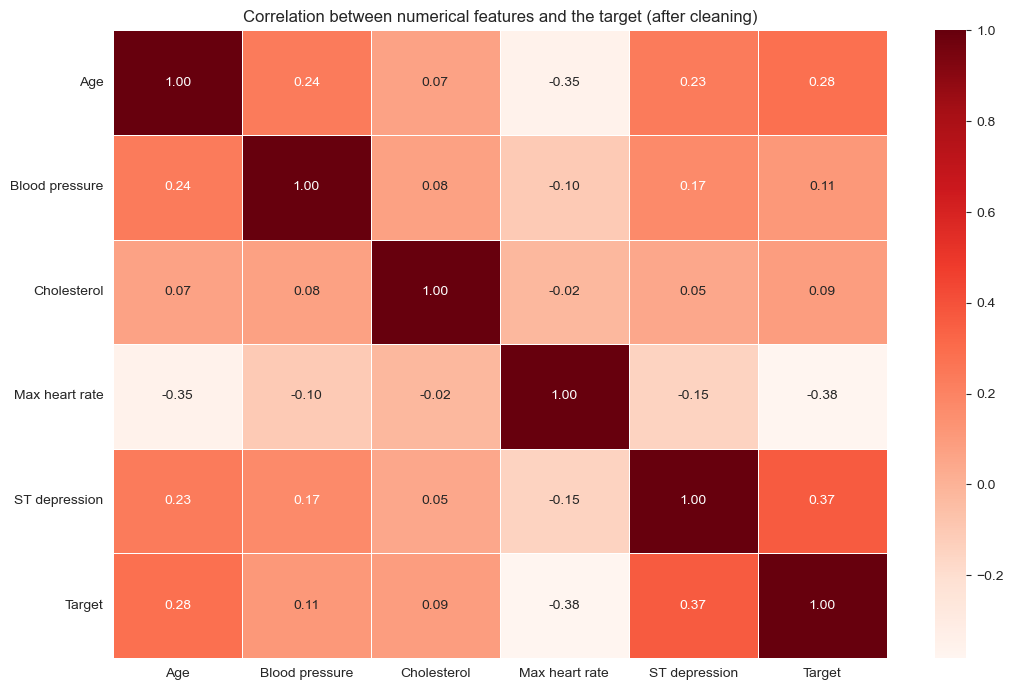

Correlation of each feature with the target after cleaning:
Target            1.000000
ST depression     0.366138
Age               0.282700
Blood pressure    0.111305
Cholesterol       0.089008
Max heart rate   -0.381864
Name: Target, dtype: float64

Correlation between features after cleaning:
                     Age  Blood pressure  Cholesterol  Max heart rate  \
Age             1.000000        0.238744     0.067105       -0.349715   
Blood pressure  0.238744        1.000000     0.075995       -0.102364   
Cholesterol     0.067105        0.075995     1.000000       -0.023477   
Max heart rate -0.349715       -0.102364    -0.023477        1.000000   
ST depression   0.233550        0.170730     0.045755       -0.149401   

                ST depression  
Age                  0.233550  
Blood pressure       0.170730  
Cholesterol          0.045755  
Max heart rate      -0.149401  
ST depression        1.000000  


In [29]:
# Look at the correlation between the numerical features and the target after cleaning
# This repeats the earlier heatmap to check whether the cholesterol correlation has corrected itself
numerical_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
corr = df[numerical_cols + ['target']].corr()

# Use the same short labels as the earlier heatmap so the two can be compared
corr_labels = ['Age', 'Blood pressure', 'Cholesterol', 'Max heart rate', 'ST depression', 'Target']
corr.index = corr_labels
corr.columns = corr_labels

plt.figure(figsize=(11, 7))
sns.heatmap(corr, annot=True, cmap='Reds', fmt='.2f', linewidths=0.5)
plt.title('Correlation between numerical features and the target (after cleaning)')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print the correlation of each feature with the target after cleaning, sorted, to support the heatmap
print('Correlation of each feature with the target after cleaning:\n{}'.format(corr['Target'].sort_values(ascending=False)))

# Print the correlations between the features (excluding the target) to check for multicollinearity
corr_features = corr.drop('Target', axis=1).drop('Target', axis=0)
print('\nCorrelation between features after cleaning:\n{}'.format(corr_features))

After cleaning, the cholesterol correlation with the target has changed from -0.23 to +0.09. It is now weakly positive, which is clinically more sensible since higher cholesterol is generally a risk factor rather than a protective one. The correction is not limited to the target: the feature-to-feature table shows that all of cholesterol's correlations have shifted (for example its correlation with maximum heart rate moves from 0.24 to -0.02, and with age from -0.09 to 0.07), which confirms that the 172 zero values had been distorting cholesterol's relationships across the board. The remaining correlations are essentially unchanged (ST depression 0.37, maximum heart rate -0.38, age 0.28) and no pair exceeds 0.85, so treating the zeros as missing fixed the cholesterol problem without introducing multicollinearity or distorting the rest of the data.

### Encode the categorical features

The machine learning models only work with numbers, so the categorical columns are converted to numeric codes. The columns `sex`, `cp`, `fbs`, `restecg` and `exang` are converted using category codes, where each category is mapped to an integer. The `sex` column is the sensitive attribute for the fairness analysis, so the mapping it produces (Female and Male to 0 and 1) is checked explicitly.

In [30]:
# Convert the categorical variables from string to integer codes for machine learning
# Sex is shown before and after conversion to verify the mapping, since it is the sensitive attribute
print('Sex is originally a string variable:\n{}'.format(df['sex'].value_counts()))
df['sex'] = df['sex'].astype('category').cat.codes
print('\nSex is converted to integer:\n{}'.format(df['sex'].value_counts()))

# Convert the remaining categorical variables
# The category codes are printed first, so it is clear which integer each category maps to, since cat.codes assigns them in alphabetical order
print('\nCategory codes for the remaining categorical features:')
for col in ['cp', 'fbs', 'restecg', 'exang']:
    categories = df[col].astype('category').cat.categories
    print('{} codes: {}'.format(col, {i: category for i, category in enumerate(categories)}))
    
df['cp'] = df['cp'].astype('category').cat.codes
df['fbs'] = df['fbs'].astype('category').cat.codes
df['restecg'] = df['restecg'].astype('category').cat.codes
df['exang'] = df['exang'].astype('category').cat.codes

print('\nData frame with categorical variables converted to integers:')
df.head()

Sex is originally a string variable:
sex
Male      726
Female    194
Name: count, dtype: int64

Sex is converted to integer:
sex
1    726
0    194
Name: count, dtype: int64

Category codes for the remaining categorical features:
cp codes: {0: 'asymptomatic', 1: 'atypical angina', 2: 'non-anginal', 3: 'typical angina'}
fbs codes: {0: False, 1: True}
restecg codes: {0: 'lv hypertrophy', 1: 'normal', 2: 'st-t abnormality'}
exang codes: {0: False, 1: True}

Data frame with categorical variables converted to integers:


,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num,target
0,63,1,Cleveland,3,145.0,233.0,1,0,150.0,0,2.3,0,0
1,67,1,Cleveland,0,160.0,286.0,0,0,108.0,1,1.5,2,1
2,67,1,Cleveland,0,120.0,229.0,0,0,129.0,1,2.6,1,1
3,37,1,Cleveland,2,130.0,250.0,0,1,187.0,0,3.5,0,0
4,41,0,Cleveland,1,130.0,204.0,0,0,172.0,0,1.4,0,0


### Separate the features and the target

The data is split into the feature matrix `X` and the target vector `y`. Three columns are removed from `X`: `target` (the variable being predicted), `num` (the original multi-class label that `target` was derived from, which would leak the answer), and `dataset` (the hospital label, which is a data source rather than a clinical feature and could let the model rely on the hospital instead of the patient).

In [31]:
# Separate the features from the target
# target is the label, num is the original label it was derived from, and dataset is the hospital source, so all three are removed from the features
X = df.drop(['target', 'num', 'dataset'], axis=1)
y = df['target']

# Confirm the feature columns that will go into the models
print('Feature columns:\n{}'.format(X.columns.tolist()))
print('\nShape of X: {}, shape of y: {}'.format(X.shape, y.shape))
X.head()

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak']

Shape of X: (920, 10), shape of y: (920,)


,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak
0,63,1,3,145.0,233.0,1,0,150.0,0,2.3
1,67,1,0,160.0,286.0,0,0,108.0,1,1.5
2,67,1,0,120.0,229.0,0,0,129.0,1,2.6
3,37,1,2,130.0,250.0,0,1,187.0,0,3.5
4,41,0,1,130.0,204.0,0,0,172.0,0,1.4


### Split into training and test sets

The data is split into a training set and a test set before any scaling or resampling, so that no information from the test set leaks into the preparation of the training data. A test size of 20% is used, and the split is stratified by the target so that the proportion of patients with and without heart disease is the same in both sets. The random state is fixed so that the split is reproducible.

In [32]:
# Import the train/test split function
from sklearn.model_selection import train_test_split

# Split into training and test sets before any scaling or resampling to avoid leakage
# stratify=y keeps the same disease rate in both sets, and the random state makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=random_state)

# Confirm the sizes and that the disease rate is preserved in both sets
print('Training set: {} patients'.format(X_train.shape[0]))
print('Test set: {} patients'.format(X_test.shape[0]))
print('\nDisease rate in training set:\n{}'.format(y_train.value_counts(normalize=True)))
print('\nDisease rate in test set:\n{}'.format(y_test.value_counts(normalize=True)))

Training set: 736 patients
Test set: 184 patients

Disease rate in training set:
target
1    0.552989
0    0.447011
Name: proportion, dtype: float64

Disease rate in test set:
target
1    0.554348
0    0.445652
Name: proportion, dtype: float64


### Scale the features

The features are scaled to a 0-1 range using MinMaxScaler so that variables with larger ranges (such as cholesterol) do not dominate variables with smaller ranges (such as ST depression). This mainly matters for Logistic Regression; tree-based models are not affected by scaling, but the same scaled data is used for all models for consistency. The scaler is fitted only on the training set and then applied to the test set, so that no information from the test set leaks into the scaling.

In [33]:
# Import the scaler
from sklearn.preprocessing import MinMaxScaler

# Scale features to a 0-1 range so that variables with larger ranges do not dominate the learning process
# The scaler is fitted only on the training set to avoid leaking information from the test set
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Confirm the scaling worked by checking the min and max of the training features
print('Minimum of scaled training features: {}'.format(X_train.min()))
print('Maximum of scaled training features: {}'.format(X_train.max()))

Minimum of scaled training features: 0.0
Maximum of scaled training features: 1.0


## 4. Feature Selection

Before training the models, the features are checked to decide whether any of them should be removed. This is done in two steps. First the correlation between every pair of features is examined to look for multicollinearity, which is when two features carry almost the same information so that one of them adds little. Then the strength of association between each feature and the target is checked using several scoring methods. The more detailed feature importance that is central to this project, including the comparison between male and female patients, is left to the SHAP analysis later on, which is better suited to that purpose.

### Multicollinearity between features

The correlation between every pair of features is examined first. If two features were very strongly correlated they would carry almost the same information, so one of them could be removed without losing much. The scaled training features are used here, and because correlation is not affected by scaling the values are the same as on the original data.

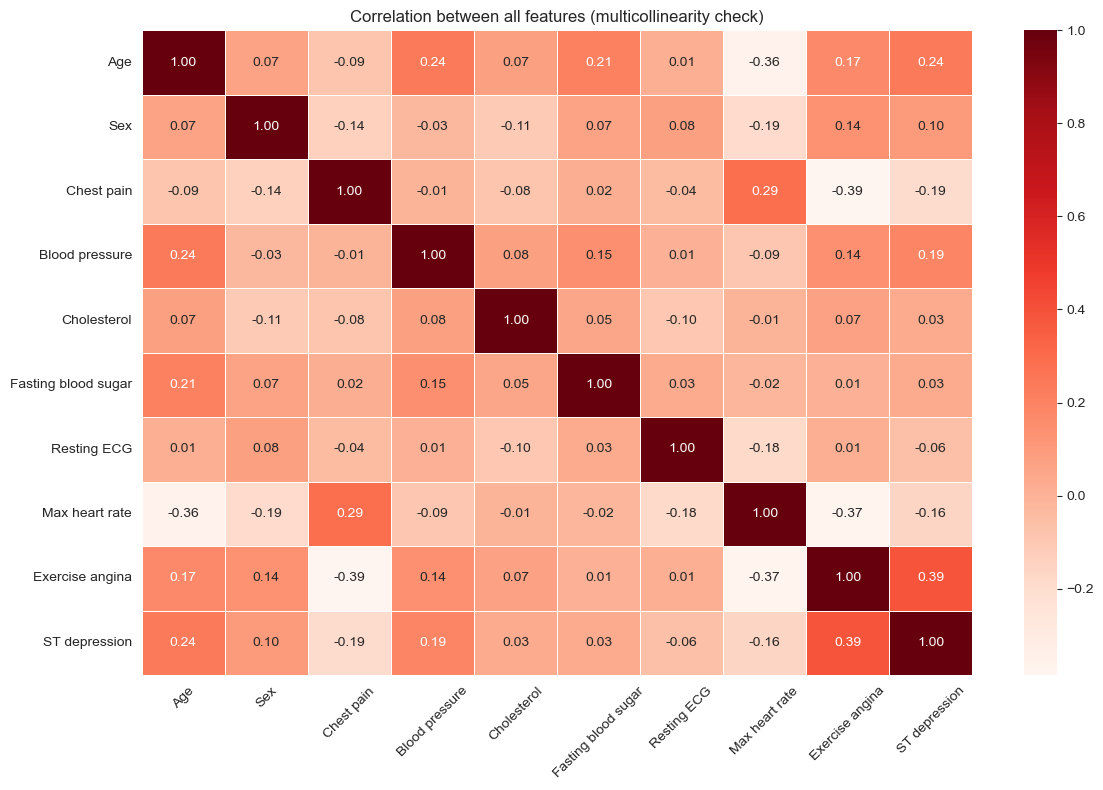

Correlation of each feature with the target:
target      1.000000
exang       0.430149
oldpeak     0.363600
age         0.309624
sex         0.304964
trestbps    0.111842
fbs         0.094818
chol        0.092024
restecg     0.055191
cp         -0.364670
thalch     -0.385915
Name: target, dtype: float64

Correlation between features:
               age       sex        cp  trestbps      chol       fbs  \
age       1.000000  0.068070 -0.087838  0.239541  0.074914  0.209297   
sex       0.068070  1.000000 -0.137173 -0.025984 -0.106324  0.068406   
cp       -0.087838 -0.137173  1.000000 -0.007160 -0.084085  0.017238   
trestbps  0.239541 -0.025984 -0.007160  1.000000  0.078093  0.147229   
chol      0.074914 -0.106324 -0.084085  0.078093  1.000000  0.051351   
fbs       0.209297  0.068406  0.017238  0.147229  0.051351  1.000000   
restecg   0.013926  0.075053 -0.043238  0.008767 -0.095277  0.030289   
thalch   -0.363382 -0.189961  0.286142 -0.089030 -0.010297 -0.015813   
exang     0.1663

In [34]:
# Look at the correlation between every pair of features to check for multicollinearity
# A heatmap makes it easy to see whether any two features carry almost the same information
# The scaled training data is wrapped back into a DataFrame so the feature names are available
X_train_df = pd.DataFrame(X_train, columns=X.columns)
corr = X_train_df.corr()

# Use short readable labels so the heatmap stays clear, matching the labels used in the earlier heatmaps
corr_labels = ['Age', 'Sex', 'Chest pain', 'Blood pressure', 'Cholesterol', 'Fasting blood sugar', 'Resting ECG', 'Max heart rate', 'Exercise angina', 'ST depression']
corr.index = corr_labels
corr.columns = corr_labels

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='Reds', fmt='.2f', linewidths=0.5)
plt.title('Correlation between all features (multicollinearity check)')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print the correlation of each feature with the target, sorted, to show which features are most related to heart disease
X_train_with_target = X_train_df.copy()
X_train_with_target['target'] = y_train.values
print('Correlation of each feature with the target:\n{}'.format(X_train_with_target.corr()['target'].sort_values(ascending=False)))

# Print the correlations between the features to check that no pair is too highly correlated
print('\nCorrelation between features:\n{}'.format(X_train_df.corr()))

The heatmap and the correlation table show that no pair of features is strongly correlated. The strongest correlation between any two different features is only 0.39 (between exercise-induced angina and ST depression), which is far below the common threshold of 0.85 that would suggest two features carry redundant information. There is therefore no multicollinearity problem and no feature needs to be removed for this reason. The correlation with the target also gives an early indication of which features matter most: maximum heart rate (-0.39), exercise-induced angina (0.43), ST depression (0.36), chest pain type (-0.36), age (0.31) and sex (0.30) show the strongest relationships, while resting blood pressure, fasting blood sugar, cholesterol and resting ECG are more weakly related. This is only a first look using simple pairwise correlation, and the importance of each feature is examined more carefully in the next step.

### Univariate feature importance

The strength of the relationship between each feature and the target is now checked using four different scoring methods: chi-squared, the ANOVA F-test, mutual information and the feature importances from an Extra Trees model. Using several methods gives more confidence than relying on a single one, since no single method works best on every dataset. If all four methods agreed that the same feature was clearly the weakest, that feature would be a candidate for removal. The scaled training data is used so that chi-squared, which requires non-negative values, can be applied alongside the other methods.

In [35]:
# Import the feature selection tools and the Extra Trees model
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.ensemble import ExtraTreesClassifier

# Wrap the scaled training data into a DataFrame so the feature names can be used as labels
X_train_df = pd.DataFrame(X_train, columns=X.columns)

# Map the short column names to readable labels so the plots are clear, matching the labels used in the heatmaps
readable_labels = {'age': 'Age', 'sex': 'Sex', 'cp': 'Chest pain', 'trestbps': 'Blood pressure', 'chol': 'Cholesterol', 'fbs': 'Fasting blood sugar', 'restecg': 'Resting ECG', 'thalch': 'Max heart rate', 'exang': 'Exercise angina', 'oldpeak': 'ST depression'}

# Score the features with chi-squared, which needs non-negative values, so the scaled 0-1 data is used
chi2_test = SelectKBest(score_func=chi2, k='all').fit(X_train_df, y_train)
chi2_sorted = pd.Series(data=chi2_test.scores_, index=X.columns).sort_values()

# Repeat with the ANOVA F-test scoring function
ftest = SelectKBest(score_func=f_classif, k='all').fit(X_train_df, y_train)
ftest_sorted = pd.Series(data=ftest.scores_, index=X.columns).sort_values()

# Repeat with mutual information, with a fixed random state so the scores are reproducible
mi_scores = mutual_info_classif(X_train_df, y_train, random_state=random_state)
mitest_sorted = pd.Series(data=mi_scores, index=X.columns).sort_values()

# Use an Extra Trees model as an alternative method that scores importance while learning to predict
xtrees = ExtraTreesClassifier(random_state=random_state).fit(X_train_df, y_train)
xtrees_sorted = pd.Series(data=xtrees.feature_importances_, index=X.columns).sort_values()

# Print the lowest scoring feature for each method to see whether they agree on a weak feature
print('Lowest scoring feature by chi2: {}'.format(chi2_sorted.index[0]))
print('Lowest scoring feature by F-test: {}'.format(ftest_sorted.index[0]))
print('Lowest scoring feature by MI: {}'.format(mitest_sorted.index[0]))
print('Lowest scoring feature by ExtraTrees: {}'.format(xtrees_sorted.index[0]))

Lowest scoring feature by chi2: chol
Lowest scoring feature by F-test: restecg
Lowest scoring feature by MI: trestbps
Lowest scoring feature by ExtraTrees: fbs


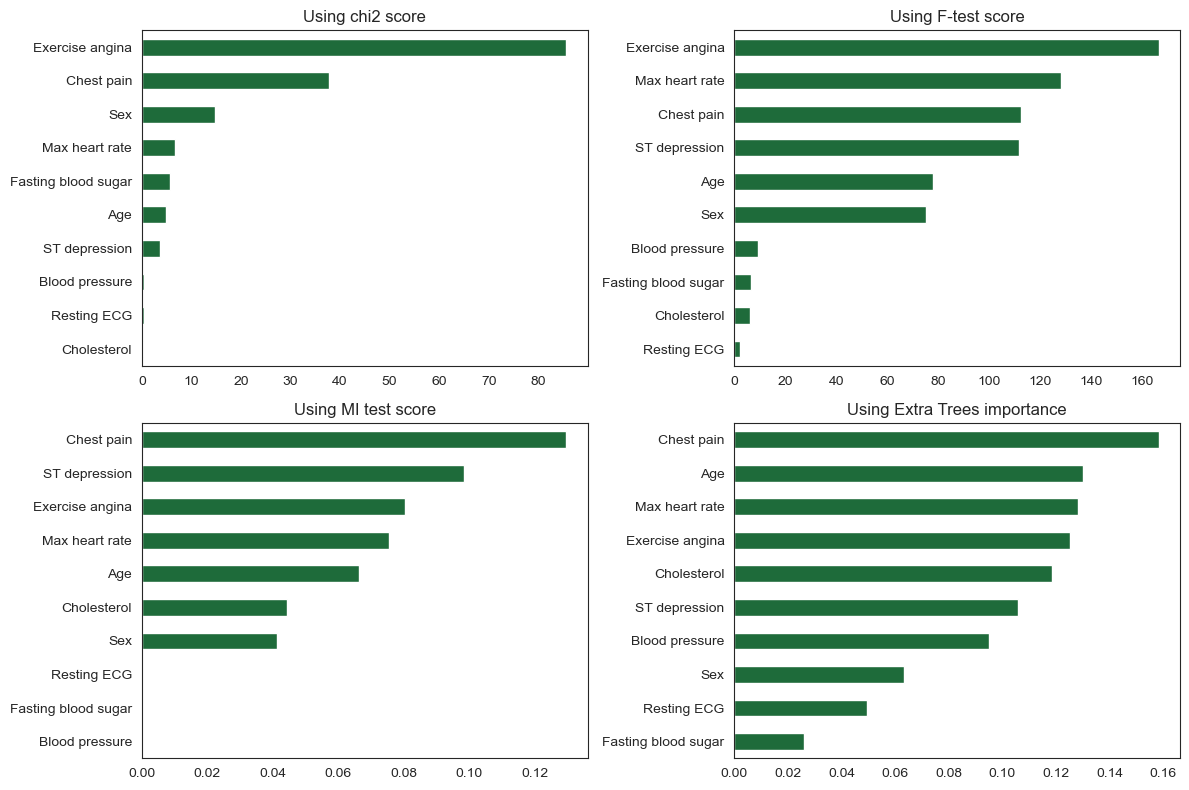

In [36]:
# Rename the index of each result to readable labels so the plots show full feature names
chi2_sorted = chi2_sorted.rename(index=readable_labels)
ftest_sorted = ftest_sorted.rename(index=readable_labels)
mitest_sorted = mitest_sorted.rename(index=readable_labels)
xtrees_sorted = xtrees_sorted.rename(index=readable_labels)

# Plot the feature selection scores from all four methods side by side so the rankings can be compared
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
plt.subplots_adjust(wspace=0.6)
chi2_sorted.plot(kind='barh', ax=axes[0, 0], title='Using chi2 score', color='#1e6b3a')
ftest_sorted.plot(kind='barh', ax=axes[0, 1], title='Using F-test score', color='#1e6b3a')
mitest_sorted.plot(kind='barh', ax=axes[1, 0], title='Using MI test score', color='#1e6b3a')
xtrees_sorted.plot(kind='barh', ax=axes[1, 1], title='Using Extra Trees importance', color='#1e6b3a')
plt.tight_layout()
plt.show()

The four methods do not agree on a single weakest feature. Chi-squared ranks cholesterol lowest, the F-test ranks resting ECG lowest, mutual information ranks resting blood pressure lowest, and the Extra Trees model ranks fasting blood sugar lowest. Because no feature is consistently ranked as the weakest across all four methods, there is no clear candidate for removal, so all ten features are kept for modelling. This matches what would be expected for this dataset, since every feature is a recognised clinical measurement rather than an arbitrary variable.

These scoring methods are only a first check, because each one looks at a single feature in isolation and ignores how features interact and which direction they push a prediction. The more detailed feature importance that matters most for this project is produced later by SHAP, which works from the trained models themselves, shows whether each feature pushes a prediction towards or away from disease, and can be split by sex to compare how the models rely on each feature for male and female patients. The simple ranking here is therefore kept as background, while the SHAP analysis carries the main weight of the importance and fairness discussion.

## 5. Model Training and Evaluation

Three classification models are trained and compared: Logistic Regression as a linear baseline, Random Forest as a tree-based ensemble, and XGBoost as a gradient boosting method. Each model is evaluated using 5-fold cross-validation on the training set and a range of metrics on the held-out test set: accuracy, precision, recall, F1-score and AUC-ROC. A confusion matrix is also produced for each model. The same training and test split prepared earlier is used for all three models so that the comparison is fair.

In [37]:
# Import the three classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Import cross-validation and the evaluation metrics
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix

In [38]:
def train_and_evaluate(model, X_train, X_test, y_train, y_test):
    """
    Train and evaluate a classification model using cross-validation on the 
    training data and a range of metrics on the separate test set, and display a confusion matrix.
    """
    print('\nResults from algorithm {}:'.format(model))
    
    # Cross-validation accuracy gives an indication of how much the accuracy varies
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    print('Mean cross-validation accuracy is {:.4f} with SD {:.4f}'
          .format(np.mean(scores), np.std(scores)))
    
    # Fit the model using all of the training data
    learnt_model = model.fit(X_train, y_train)
    print('\nAccuracy on training data is {:.4f}\n'.format(model.score(X_train, y_train)))

    # Use predict() to predict the target values for the test set
    y_pred = model.predict(X_test)

    # Use predict_proba() to get the probability of disease for the AUC-ROC score
    y_proba = model.predict_proba(X_test)[:, 1]

    # Print the test metrics, including AUC-ROC which is not threshold dependent
    print('Test data metrics: accuracy={:.4f}, f1={:.4f}, precision={:.4f}, recall={:.4f}, auc={:.4f}'
          .format(accuracy_score(y_true=y_test, y_pred=y_pred),
                  f1_score(y_true=y_test, y_pred=y_pred),
                  precision_score(y_true=y_test, y_pred=y_pred),
                  recall_score(y_true=y_test, y_pred=y_pred),
                  roc_auc_score(y_true=y_test, y_score=y_proba)))
    
    # Draw out a confusion matrix
    cm = confusion_matrix(y_true=y_test, y_pred=y_pred)
    plt.figure(figsize=(3, 3))
    ax = sns.heatmap(cm, annot=True, fmt='d', cmap='OrRd', cbar=False, xticklabels=['0', '1'],
                     yticklabels=['0', '1'], square=True, linewidths=8.0)
    ax.set_xlabel('Predicted disease')
    ax.set_ylabel('Actual disease')
    plt.tight_layout()
    plt.show()
    return learnt_model

### Logistic Regression

Logistic Regression is trained first as a linear baseline. It is a simple and interpretable model that draws a linear decision boundary, so it provides a useful reference point against which the more complex tree-based models can be compared. The maximum number of iterations is increased to 200 so that the solver has enough steps to converge.


Results from algorithm LogisticRegression(max_iter=200):
Mean cross-validation accuracy is 0.7758 with SD 0.0319

Accuracy on training data is 0.7840

Test data metrics: accuracy=0.7609, f1=0.7864, precision=0.7788, recall=0.7941, auc=0.8771


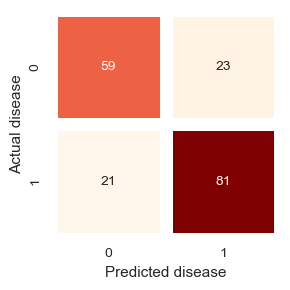

In [39]:
# Train and evaluate Logistic Regression as the linear baseline
log_reg = train_and_evaluate(LogisticRegression(max_iter=200), X_train, X_test, y_train, y_test)

### Random Forest

Random Forest is trained next as a tree-based ensemble model. Instead of fitting a single decision tree, it builds many trees on random subsets of the data and features and averages their predictions, which usually gives better performance and reduces overfitting compared with a single tree. It can also capture non-linear patterns that the linear Logistic Regression baseline cannot. The random state is fixed so that the results are reproducible.


Results from algorithm RandomForestClassifier(random_state=42):
Mean cross-validation accuracy is 0.7880 with SD 0.0217

Accuracy on training data is 1.0000

Test data metrics: accuracy=0.7989, f1=0.8263, precision=0.7928, recall=0.8627, auc=0.8870


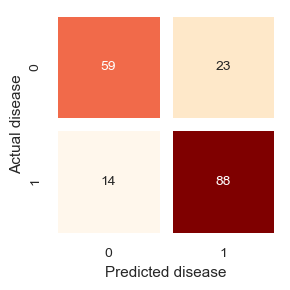

In [40]:
# Train and evaluate Random Forest as a tree-based ensemble model
rf = train_and_evaluate(RandomForestClassifier(random_state=random_state), X_train, X_test, y_train, y_test)

### XGBoost

XGBoost is the third model, a gradient boosting method that builds trees sequentially, where each new tree tries to correct the errors made by the previous ones. This often gives strong predictive performance on structured data and provides another non-linear model to compare against Random Forest. The random state is fixed for reproducibility, and the evaluation metric is set to log loss, which is the standard objective for binary classification.


Results from algorithm XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...):
Mean cross-validation accuracy is 0.7813 with SD 0.0365

Accuracy on training data is 1.0000

Test data metrics: accuracy=0.8152, f1=0.8350, precision=0.8269, recall=0.8431, auc=0.8779


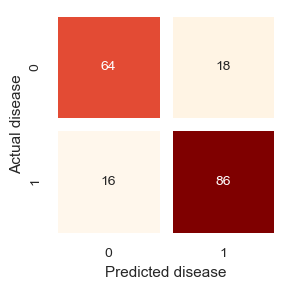

In [41]:
# Train and evaluate XGBoost as a gradient boosting model
xgb = train_and_evaluate(XGBClassifier(random_state=random_state, eval_metric='logloss'), X_train, X_test, y_train, y_test)

### Model comparison

The three default models are compared side by side using the test set metrics, together with the training accuracy to check for overfitting. This summary makes it easier to see which model performs best before any hyperparameter tuning is applied.

In [42]:
# Get the predictions and predicted probabilities for each model on the test set
log_reg_pred = log_reg.predict(X_test)
log_reg_proba = log_reg.predict_proba(X_test)[:, 1]
rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]
xgb_pred = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]

# Build a comparison table with the training accuracy and the test metrics for all three models
comparison = pd.DataFrame({
    'Logistic Regression': [log_reg.score(X_train, y_train),
                            accuracy_score(y_true=y_test, y_pred=log_reg_pred),
                            f1_score(y_true=y_test, y_pred=log_reg_pred),
                            precision_score(y_true=y_test, y_pred=log_reg_pred),
                            recall_score(y_true=y_test, y_pred=log_reg_pred),
                            roc_auc_score(y_true=y_test, y_score=log_reg_proba)],
    'Random Forest': [rf.score(X_train, y_train),
                      accuracy_score(y_true=y_test, y_pred=rf_pred),
                      f1_score(y_true=y_test, y_pred=rf_pred),
                      precision_score(y_true=y_test, y_pred=rf_pred),
                      recall_score(y_true=y_test, y_pred=rf_pred),
                      roc_auc_score(y_true=y_test, y_score=rf_proba)],
    'XGBoost': [xgb.score(X_train, y_train),
                accuracy_score(y_true=y_test, y_pred=xgb_pred),
                f1_score(y_true=y_test, y_pred=xgb_pred),
                precision_score(y_true=y_test, y_pred=xgb_pred),
                recall_score(y_true=y_test, y_pred=xgb_pred),
                roc_auc_score(y_true=y_test, y_score=xgb_proba)]
}, index=['Training accuracy', 'Test accuracy', 'F1 score', 'Precision', 'Recall', 'AUC-ROC'])

# Show the comparison rounded to four decimals for readability
print('Model comparison on the test set:\n{}'.format(comparison.round(4)))

Model comparison on the test set:
                   Logistic Regression  Random Forest  XGBoost
Training accuracy               0.7840         1.0000   1.0000
Test accuracy                   0.7609         0.7989   0.8152
F1 score                        0.7864         0.8263   0.8350
Precision                       0.7788         0.7928   0.8269
Recall                          0.7941         0.8627   0.8431
AUC-ROC                         0.8771         0.8870   0.8779


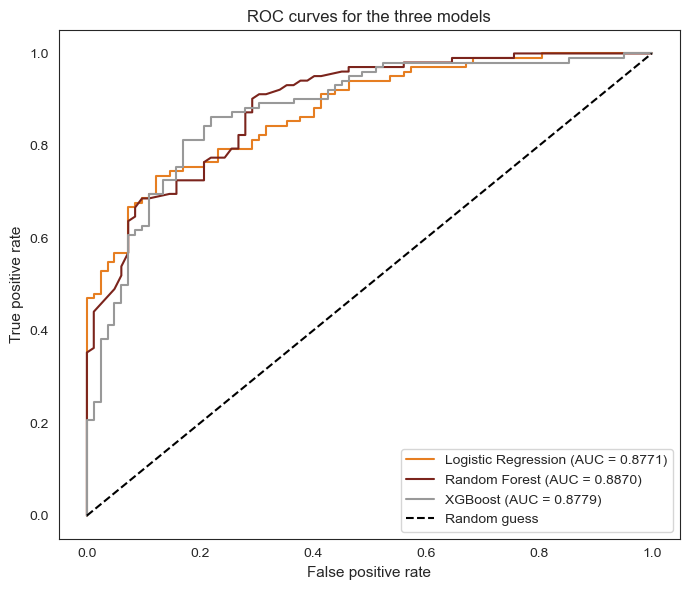

In [43]:
# Plot the ROC curve for all three models on the same axes to compare them visually
# The ROC curve shows the trade-off between the true positive rate and the false positive rate, and the area under it is the AUC reported in the table above
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 6))
# For each model, compute the false positive rate and true positive rate across thresholds, then plot the curve
log_reg_fpr, log_reg_tpr, _ = roc_curve(y_test, log_reg_proba)
plt.plot(log_reg_fpr, log_reg_tpr, label='Logistic Regression (AUC = {:.4f})'.format(roc_auc_score(y_test, log_reg_proba)), color='#e67e22')
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_proba)
plt.plot(rf_fpr, rf_tpr, label='Random Forest (AUC = {:.4f})'.format(roc_auc_score(y_test, rf_proba)), color='#7b241c')
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_proba)
plt.plot(xgb_fpr, xgb_tpr, label='XGBoost (AUC = {:.4f})'.format(roc_auc_score(y_test, xgb_proba)), color='#999999')

# Add the diagonal line that represents a model with no predictive ability (random guessing)
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random guess')
plt.title('ROC curves for the three models')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.tight_layout()
plt.show()

The comparison shows that the two tree-based models outperform the Logistic Regression baseline on the test set. XGBoost achieves the highest test accuracy (0.8152), F1 score (0.8350) and precision (0.8269), which means it makes the most correct predictions overall and has the fewest false alarms. Random Forest has the highest recall (0.8627) and the highest AUC-ROC (0.8870), which means it catches the largest proportion of patients who actually have heart disease and separates the two classes slightly better across all thresholds. The ROC curves above show this visually: all three models sit well above the diagonal random-guess line and their curves are close together, with Random Forest keeping a slightly better balance between the true positive rate and the false positive rate across the whole range. The confusion matrices make this trade-off concrete. Out of the 102 patients who actually have heart disease in the test set, Random Forest misses only 14 (false negatives), compared with 16 for XGBoost and 21 for Logistic Regression, so Random Forest makes the fewest dangerous misses. XGBoost, on the other hand, raises the fewest false alarms (18 false positives, against 23 for both Random Forest and Logistic Regression), which matches its higher precision. In a clinical setting a false negative, missing a patient who actually has the disease, is usually more serious than a false alarm, which is why recall and the false negative count matter most here. Logistic Regression is the weakest of the three on the test set, but it is still a reasonable baseline and provides a useful linear reference point.

A key observation is the difference between training and test accuracy. Logistic Regression has a training accuracy of 0.7840 and a test accuracy of 0.7609, which are very close, so it is not overfitting. In contrast, both Random Forest and XGBoost reach a training accuracy of 1.0000, meaning they classify every single training patient correctly. When a model is almost perfect on the training data but noticeably lower on the test data, it has memorised the training examples rather than learning general patterns, which is called overfitting. For tree-based ensembles this is expected behaviour with their default settings, because the trees are allowed to grow until they fit the training data exactly.

However, this overfitting does not make the models unusable. Their test performance is still strong (around 0.80), and their cross-validation scores are stable: Random Forest, for example, has a mean cross-validation accuracy of 0.7880 with a very low standard deviation of 0.0217, which means it performs consistently across different subsets of the training data rather than depending on one lucky split. This consistency suggests that the models still perform reasonably well on unseen patients despite the perfect training score. The gap between training and test accuracy will be addressed in the next section through hyperparameter tuning, which limits how complex the models can become in order to reduce overfitting while keeping their predictive performance.

## 6. Hyperparameter Tuning

The model comparison above showed that Random Forest and XGBoost reach a perfect training accuracy of 1.0000, which is a sign of overfitting. In this section the hyperparameters of each model are tuned to reduce this overfitting while keeping the predictive performance. A helper function trains a model with a given set of hyperparameters and returns its mean cross-validation accuracy, so that a range of values can be compared. The best value for each hyperparameter is chosen using cross-validation on the training set only, and the tuned models are then evaluated on the held-out test set. The test set is never used to choose the hyperparameters.

In [44]:
# Helper function that trains a model with a given set of hyperparameters and returns its mean cross-validation accuracy
# This is used to compare a range of hyperparameter values during tuning
def train_model(algorithm, hyperparams, X, y):
    """
    Use cross-validation to determine the model accuracy for a given algorithm and set of hyperparameters,
    and return the mean accuracy across the folds together with the trained model.
    """
    model = algorithm(**hyperparams)
    scores = cross_val_score(model, X, y, cv=10, scoring='accuracy')
    learnt_model = model.fit(X, y)
    return (np.mean(scores), learnt_model)

### Tuning Logistic Regression

For Logistic Regression the main hyperparameter is `C`, the inverse of the regularisation strength. A small `C` applies strong regularisation, which keeps the model simple and can prevent overfitting, while a large `C` lets the model fit the training data more closely. A range of values is tried and the mean cross-validation accuracy is recorded for each, so that the value which generalises best can be chosen. The maximum number of iterations is kept at 200 so that the solver converges.

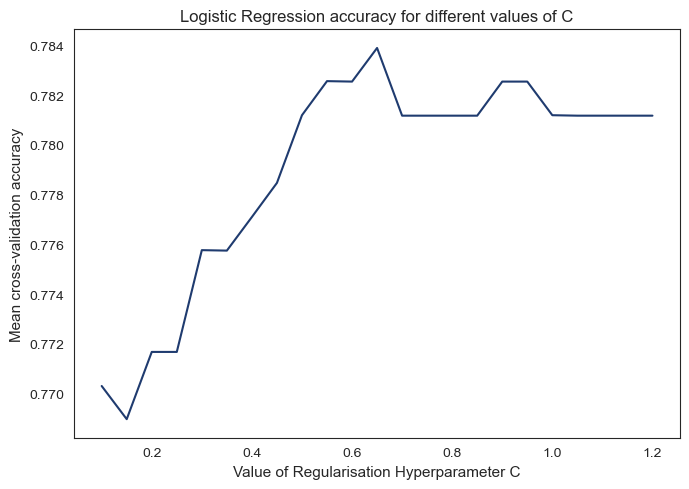

Best C value: 0.65 with cross-validation accuracy 0.7839


In [45]:
# Try a range of regularisation strengths C for Logistic Regression
# A smaller C means stronger regularisation, and the cross-validation accuracy is recorded for each value
reg_values = [0.05 * i for i in range(2, 25)]
reg_accuracy = []
for reg_strength in reg_values:
    acc, _ = train_model(LogisticRegression, {'C': reg_strength, 'max_iter': 200}, X_train, y_train)
    reg_accuracy.append(acc)

# Plot the cross-validation accuracy against the value of C to see which gives the best result
plt.figure(figsize=(7, 5))
plt.plot(reg_values, reg_accuracy, color='#1f3b6f')
plt.title('Logistic Regression accuracy for different values of C')
plt.ylabel('Mean cross-validation accuracy')
plt.xlabel('Value of Regularisation Hyperparameter C')
plt.tight_layout()
plt.show()

# Find and report the C value that gives the highest cross-validation accuracy
best_C = reg_values[np.argmax(reg_accuracy)]
print('Best C value: {:.2f} with cross-validation accuracy {:.4f}'.format(best_C, np.max(reg_accuracy)))

### Tuning Random Forest

Random Forest overfitted on the default settings, reaching a perfect training accuracy of 1.0000. Two hyperparameters are used together to control this. The first is `max_depth`, which limits how deep each tree in the forest can grow, and a range of depth values is tried so that the depth which generalises best can be chosen. The second is `min_samples_leaf`, which is fixed at 5 so that every leaf must contain at least five patients rather than being allowed to split down to a single patient, which is the default behaviour that let the trees fit the training data exactly. The mean cross-validation accuracy is recorded for each depth value, and the random state is fixed so that the results are reproducible.

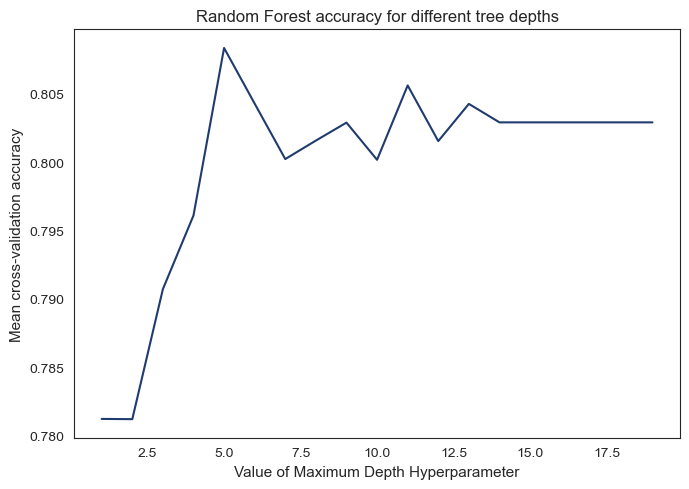

Best max_depth value: 5 with cross-validation accuracy 0.8083


In [46]:
# Try a range of maximum depth values for Random Forest to control overfitting
# A smaller depth keeps the trees simpler, and min_samples_leaf is fixed at 5 so each leaf needs at least five patients, which also reduces overfitting
depth_values = [i for i in range(1, 20)]
depth_accuracy = []
for depth in depth_values:
    acc, _ = train_model(RandomForestClassifier, {'max_depth': depth, 'min_samples_leaf': 5, 'random_state': random_state}, X_train, y_train)
    depth_accuracy.append(acc)

# Plot the cross-validation accuracy against the tree depth to see which gives the best result
plt.figure(figsize=(7, 5))
plt.plot(depth_values, depth_accuracy, color='#1f3b6f')
plt.title('Random Forest accuracy for different tree depths')
plt.ylabel('Mean cross-validation accuracy')
plt.xlabel('Value of Maximum Depth Hyperparameter')
plt.tight_layout()
plt.show()

# Find and report the depth value that gives the highest cross-validation accuracy
best_depth = depth_values[np.argmax(depth_accuracy)]
print('Best max_depth value: {} with cross-validation accuracy {:.4f}'.format(best_depth, np.max(depth_accuracy)))

### Tuning XGBoost

XGBoost also overfitted on the default settings, reaching a perfect training accuracy of 1.0000. Two settings are used together to control this. The `max_depth` is tuned across a range of values to find the depth which generalises best, while the `learning_rate` is fixed at 0.05 with `n_estimators` set to 150, so that the model learns slowly over more trees rather than fitting the training data quickly. A lower learning rate makes each tree contribute a smaller correction, which reduces overfitting. The mean cross-validation accuracy is recorded for each depth value, and the random state is fixed so that the results are reproducible.

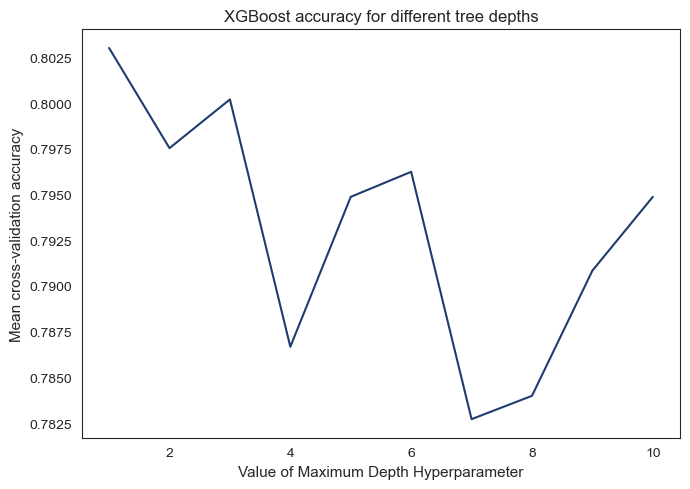

Best max_depth value: 1 with cross-validation accuracy 0.8030


In [47]:
# Try a range of maximum depth values for XGBoost to control overfitting
# A smaller depth keeps the trees simpler, and learning_rate is fixed at 0.05 with 150 trees so the model learns slowly and carefully, which also reduces overfitting
# The cross-validation accuracy is recorded for each value
xgb_depth_values = [i for i in range(1, 11)]
xgb_depth_accuracy = []
for depth in xgb_depth_values:
    acc, _ = train_model(XGBClassifier, {'max_depth': depth, 'learning_rate': 0.05, 'n_estimators': 150, 'random_state': random_state, 'eval_metric': 'logloss'}, X_train, y_train)
    xgb_depth_accuracy.append(acc)

# Plot the cross-validation accuracy against the tree depth to see which gives the best result
plt.figure(figsize=(7, 5))
plt.plot(xgb_depth_values, xgb_depth_accuracy, color='#1f3b6f')
plt.title('XGBoost accuracy for different tree depths')
plt.ylabel('Mean cross-validation accuracy')
plt.xlabel('Value of Maximum Depth Hyperparameter')
plt.tight_layout()
plt.show()

# Find and report the depth value that gives the highest cross-validation accuracy
best_xgb_depth = xgb_depth_values[np.argmax(xgb_depth_accuracy)]
print('Best max_depth value: {} with cross-validation accuracy {:.4f}'.format(best_xgb_depth, np.max(xgb_depth_accuracy)))

### Evaluating the tuned models

Each model is now retrained with its best hyperparameter value found above and evaluated on the test set, using the same `train_and_evaluate` function as for the default models so that the results can be compared directly. The most important thing to check is the training accuracy of Random Forest and XGBoost: if it has dropped from the perfect 1.0000 seen earlier, the overfitting has been reduced. Each model is taken with the best value identified in its tuning plot above, and these values are stated for each model below.

#### Tuned Logistic Regression

Logistic Regression is retrained with C=0.65, the best regularisation strength found above, to see whether the slightly stronger regularisation changes its performance.


Results from algorithm LogisticRegression(C=0.65, max_iter=200):
Mean cross-validation accuracy is 0.7758 with SD 0.0336

Accuracy on training data is 0.7853

Test data metrics: accuracy=0.7663, f1=0.7923, precision=0.7810, recall=0.8039, auc=0.8772


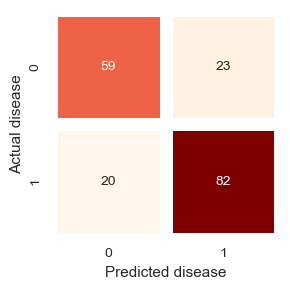

In [48]:
# Retrain Logistic Regression with the best C value and evaluate on the test set
tuned_log_reg = train_and_evaluate(LogisticRegression(C=best_C, max_iter=200), X_train, X_test, y_train, y_test)

#### Tuned Random Forest

Random Forest is retrained with max_depth=5, the best depth found above, together with min_samples_leaf fixed at 5, to check whether these limits reduce the overfitting seen in the default model.


Results from algorithm RandomForestClassifier(max_depth=5, min_samples_leaf=5, random_state=42):
Mean cross-validation accuracy is 0.7948 with SD 0.0318

Accuracy on training data is 0.8546

Test data metrics: accuracy=0.7935, f1=0.8241, precision=0.7807, recall=0.8725, auc=0.9033


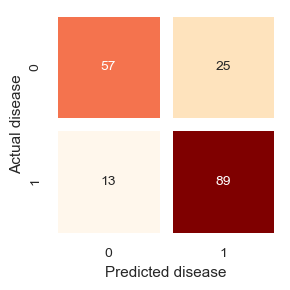

In [49]:
# Retrain Random Forest with the best max_depth value and min_samples_leaf fixed at 5, then evaluate on the test set
tuned_rf = train_and_evaluate(RandomForestClassifier(max_depth=best_depth, min_samples_leaf=5, random_state=random_state), X_train, X_test, y_train, y_test)

#### Tuned XGBoost

XGBoost is retrained with max_depth=1, the best depth found above, together with the lower learning_rate of 0.05 and 150 trees, to check whether these settings reduce the overfitting seen in the default model.


Results from algorithm XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=1, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=None,
              num_parallel_tree=None, ...):
Mean cross-validation accuracy is 0.7962 with SD 0.0305

Accuracy on training data is 0.8152

Test data metrics: accuracy=0.8152, f1=0.8381, precision=0.8148, recall=0.8627, auc=0.9082


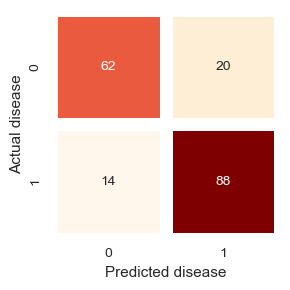

In [50]:
# Retrain XGBoost with the best max_depth value, learning_rate fixed at 0.05 and 150 trees, then evaluate on the test set
tuned_xgb = train_and_evaluate(XGBClassifier(max_depth=best_xgb_depth, learning_rate=0.05, n_estimators=150, random_state=random_state, eval_metric='logloss'), X_train, X_test, y_train, y_test)


### Comparing the default and tuned models

The table below puts the default and tuned versions of each model side by side, so that the effect of the hyperparameter tuning can be seen directly. The training accuracy is included because the main aim of the tuning was to reduce the overfitting seen in the default Random Forest and XGBoost, both of which reached a perfect training accuracy of 1.0000.

In [51]:
# Get the predictions and probabilities for the three tuned models on the test set
tuned_log_reg_pred = tuned_log_reg.predict(X_test)
tuned_log_reg_proba = tuned_log_reg.predict_proba(X_test)[:, 1]
tuned_rf_pred = tuned_rf.predict(X_test)
tuned_rf_proba = tuned_rf.predict_proba(X_test)[:, 1]
tuned_xgb_pred = tuned_xgb.predict(X_test)
tuned_xgb_proba = tuned_xgb.predict_proba(X_test)[:, 1]

# Build a comparison table with the default and tuned version of each model side by side
tuned_comparison = pd.DataFrame({
    'LR default': [log_reg.score(X_train, y_train),
                   accuracy_score(y_true=y_test, y_pred=log_reg_pred),
                   f1_score(y_true=y_test, y_pred=log_reg_pred),
                   precision_score(y_true=y_test, y_pred=log_reg_pred),
                   recall_score(y_true=y_test, y_pred=log_reg_pred),
                   roc_auc_score(y_true=y_test, y_score=log_reg_proba)],
    'LR tuned': [tuned_log_reg.score(X_train, y_train),
                 accuracy_score(y_true=y_test, y_pred=tuned_log_reg_pred),
                 f1_score(y_true=y_test, y_pred=tuned_log_reg_pred),
                 precision_score(y_true=y_test, y_pred=tuned_log_reg_pred),
                 recall_score(y_true=y_test, y_pred=tuned_log_reg_pred),
                 roc_auc_score(y_true=y_test, y_score=tuned_log_reg_proba)],
    'RF default': [rf.score(X_train, y_train),
                   accuracy_score(y_true=y_test, y_pred=rf_pred),
                   f1_score(y_true=y_test, y_pred=rf_pred),
                   precision_score(y_true=y_test, y_pred=rf_pred),
                   recall_score(y_true=y_test, y_pred=rf_pred),
                   roc_auc_score(y_true=y_test, y_score=rf_proba)],
    'RF tuned': [tuned_rf.score(X_train, y_train),
                 accuracy_score(y_true=y_test, y_pred=tuned_rf_pred),
                 f1_score(y_true=y_test, y_pred=tuned_rf_pred),
                 precision_score(y_true=y_test, y_pred=tuned_rf_pred),
                 recall_score(y_true=y_test, y_pred=tuned_rf_pred),
                 roc_auc_score(y_true=y_test, y_score=tuned_rf_proba)],
    'XGBoost default': [xgb.score(X_train, y_train),
                        accuracy_score(y_true=y_test, y_pred=xgb_pred),
                        f1_score(y_true=y_test, y_pred=xgb_pred),
                        precision_score(y_true=y_test, y_pred=xgb_pred),
                        recall_score(y_true=y_test, y_pred=xgb_pred),
                        roc_auc_score(y_true=y_test, y_score=xgb_proba)],
    'XGBoost tuned': [tuned_xgb.score(X_train, y_train),
                      accuracy_score(y_true=y_test, y_pred=tuned_xgb_pred),
                      f1_score(y_true=y_test, y_pred=tuned_xgb_pred),
                      precision_score(y_true=y_test, y_pred=tuned_xgb_pred),
                      recall_score(y_true=y_test, y_pred=tuned_xgb_pred),
                      roc_auc_score(y_true=y_test, y_score=tuned_xgb_proba)]
}, index=['Training accuracy', 'Test accuracy', 'F1 score', 'Precision', 'Recall', 'AUC-ROC'])

# Show the comparison rounded to four decimals for readability
print('Default vs tuned comparison on the test set:\n{}'.format(tuned_comparison.round(4)))

Default vs tuned comparison on the test set:
                   LR default  LR tuned  RF default  RF tuned  \
Training accuracy      0.7840    0.7853      1.0000    0.8546   
Test accuracy          0.7609    0.7663      0.7989    0.7935   
F1 score               0.7864    0.7923      0.8263    0.8241   
Precision              0.7788    0.7810      0.7928    0.7807   
Recall                 0.7941    0.8039      0.8627    0.8725   
AUC-ROC                0.8771    0.8772      0.8870    0.9033   

                   XGBoost default  XGBoost tuned  
Training accuracy           1.0000         0.8152  
Test accuracy               0.8152         0.8152  
F1 score                    0.8350         0.8381  
Precision                   0.8269         0.8148  
Recall                      0.8431         0.8627  
AUC-ROC                     0.8779         0.9082  


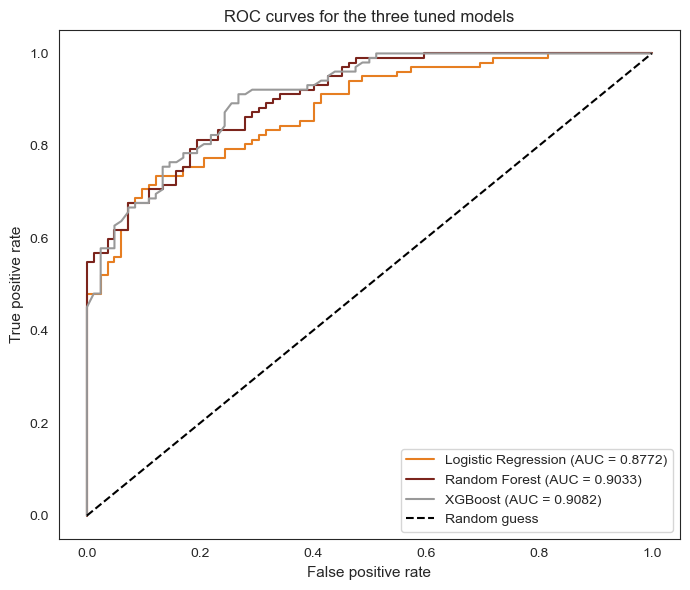

In [52]:
# Plot the ROC curve for the three tuned models on the same axes to compare them visually
# This uses the same style as the ROC curve for the default models so the two can be compared
plt.figure(figsize=(7, 6))

# For each tuned model, compute the false positive rate and true positive rate across thresholds, then plot the curve
tuned_log_reg_fpr, tuned_log_reg_tpr, _ = roc_curve(y_test, tuned_log_reg_proba)
plt.plot(tuned_log_reg_fpr, tuned_log_reg_tpr, label='Logistic Regression (AUC = {:.4f})'.format(roc_auc_score(y_test, tuned_log_reg_proba)), color='#e67e22')
tuned_rf_fpr, tuned_rf_tpr, _ = roc_curve(y_test, tuned_rf_proba)
plt.plot(tuned_rf_fpr, tuned_rf_tpr, label='Random Forest (AUC = {:.4f})'.format(roc_auc_score(y_test, tuned_rf_proba)), color='#7b241c')
tuned_xgb_fpr, tuned_xgb_tpr, _ = roc_curve(y_test, tuned_xgb_proba)
plt.plot(tuned_xgb_fpr, tuned_xgb_tpr, label='XGBoost (AUC = {:.4f})'.format(roc_auc_score(y_test, tuned_xgb_proba)), color='#999999')

# Add the diagonal line that represents a model with no predictive ability (random guessing)
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random guess')
plt.title('ROC curves for the three tuned models')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.tight_layout()
plt.show()

The comparison shows that the effect of the tuning was very different for each model. For Logistic Regression almost nothing changed, which is expected: the default model was already not overfitting (training 0.7840 against test 0.7609), so regularising it slightly with C=0.65 left the training accuracy at 0.7853 and the test scores essentially the same. The tuning mattered most for the two tree-based models, and this time it reduced the overfitting in both of them.

For XGBoost the tuning worked as intended. Combining shallow trees (max_depth=1) with a low learning rate of 0.05 over 150 trees brought the training accuracy down from a perfect 1.0000 to 0.8152, a clear sign that overfitting has been reduced. Importantly this did not cost any test performance, and in fact improved it: the tuned XGBoost keeps the same test accuracy (0.8152), improves its recall from 0.8431 to 0.8627, and reaches the highest AUC-ROC of any model in the table (0.9082, up from 0.8779). The recall improves while precision stays high (0.8148), so the tuned model catches more true cases without raising many more false alarms. A simpler model that generalises better is exactly the outcome that tuning is meant to produce.

For Random Forest the tuning also reduced the overfitting. With the best depth found by cross-validation (max_depth=5) and min_samples_leaf fixed at 5, the training accuracy dropped from a perfect 1.0000 to 0.8546, so the forest no longer fits every training patient exactly. Requiring at least five patients in each leaf was the key change here, since the default setting allowed the trees to split all the way down to single patients. This did not harm the model: its test accuracy is almost unchanged at 0.7935, its recall improves to 0.8725, the highest of any model, and its AUC-ROC improves to 0.9033. Limiting the depth and leaf size therefore made the forest simpler and less overfitted while slightly improving how well it separates the two classes.

The confusion matrices make this concrete in terms of the errors that matter most clinically. Out of the 102 patients who actually have heart disease in the test set, the tuned Random Forest misses only 13 (false negatives), the tuned XGBoost misses 14, and Logistic Regression misses 20, so both tree-based models make very few dangerous misses. Compared with the default versions, the tuning lowered the false negatives for all three models (from 14 to 13 for Random Forest, 16 to 14 for XGBoost and 21 to 20 for Logistic Regression), which means fewer patients with disease are overlooked. This came with a small rise in false positives for the tree-based models (Random Forest from 23 to 25 and XGBoost from 18 to 20), which is the expected cost of catching more true cases. In a clinical setting a false negative, missing a patient who actually has the disease, is usually more serious than a false alarm, so reducing the false negatives is the more valuable change.

Taken together, the tuning reduced the overfitting in both tree-based models, and the tuned XGBoost is the strongest model overall: it has the highest AUC-ROC (0.9082), the highest test accuracy (0.8152), and a strong recall (0.8627), so it combines good predictive performance with reduced overfitting. The tuned Random Forest is a close second, with the highest recall (0.8725) and a very similar AUC-ROC (0.9033). For this reason the explainability and fairness analysis in the following sections focuses on the tuned models, with XGBoost as the main model of interest, while still keeping all three for comparison.

## 7. Explainability (SHAP and LIME)

The models predict heart disease with reasonable accuracy but do not show *why* a prediction was made. This section uses two explainability tools, SHAP and LIME, to see which features drive the predictions and whether the models rely on them differently for female and male patients.

SHAP (SHapley Additive exPlanations) gives each feature a value showing how much it pushed a prediction up or down. It is used in three roles, kept separate throughout:

- **Global SHAP** ranks which features matter most across all patients.
- **Local SHAP** explains a single patient's prediction, the kind of case-level explanation a clinician would need.
- **Gender-stratified SHAP** compares feature importance for female and male patients separately, which is the bridge to the fairness analysis.

LIME (Local Interpretable Model-agnostic Explanations) is then used as a second check on the local explanations. The analysis focuses on the tuned XGBoost, with the tuned Random Forest examined afterwards as a comparison. Both are tree-based, so TreeExplainer is used to compute their SHAP values.

### SHAP setup

A TreeExplainer is built for the tuned XGBoost model and the SHAP values are computed on the test set, so the explanations describe how the model behaves on patients it did not see during training. Because the features were scaled during preprocessing, the scaled test set is wrapped back into a data frame with the original column names so that the plots show readable feature names.

In [53]:
# Import the SHAP library for explaining the model predictions
import shap

# Wrap the scaled test set back into a data frame so the feature names are available for the SHAP plots
X_test_df = pd.DataFrame(X_test, columns=X.columns)

# Build a TreeExplainer for the tuned XGBoost model
# TreeExplainer is the fast and exact SHAP algorithm for tree-based models
explainer_xgb = shap.TreeExplainer(tuned_xgb)

# Compute the SHAP values for every patient in the test set
shap_values_xgb = explainer_xgb.shap_values(X_test_df)

# Confirm the shape of the SHAP values: one value per patient per feature
print('SHAP values computed for the tuned XGBoost model')
print('Shape of the SHAP values: {}'.format(shap_values_xgb.shape))
print('This is {} patients and {} features'.format(shap_values_xgb.shape[0], shap_values_xgb.shape[1]))

SHAP values computed for the tuned XGBoost model
Shape of the SHAP values: (184, 10)
This is 184 patients and 10 features


### Global SHAP

Global SHAP summarises how the model uses each feature across all patients in the test set. Two plots are produced. The first is a summary (beeswarm) plot, where each row is a feature ranked by importance and each dot is one patient: the horizontal position shows how much that feature pushed that patient's prediction towards or away from heart disease, and the colour shows whether the feature value was high or low. The second is a bar plot showing the mean absolute SHAP value for each feature, which is a simpler ranking of overall importance. Together they show not just which features matter most, but in which direction they push the prediction.

In [54]:
# Map the short column names to readable labels for the SHAP plots, matching the labels
readable_labels = {'age': 'Age', 'sex': 'Sex', 'cp': 'Chest pain', 'trestbps': 'Blood pressure', 'chol': 'Cholesterol', 'fbs': 'Fasting blood sugar', 'restecg': 'Resting ECG', 'thalch': 'Max heart rate', 'exang': 'Exercise angina', 'oldpeak': 'ST depression'}

# Build a version of the test set with readable feature names so the SHAP plots are clear
X_test_display = X_test_df.rename(columns=readable_labels)

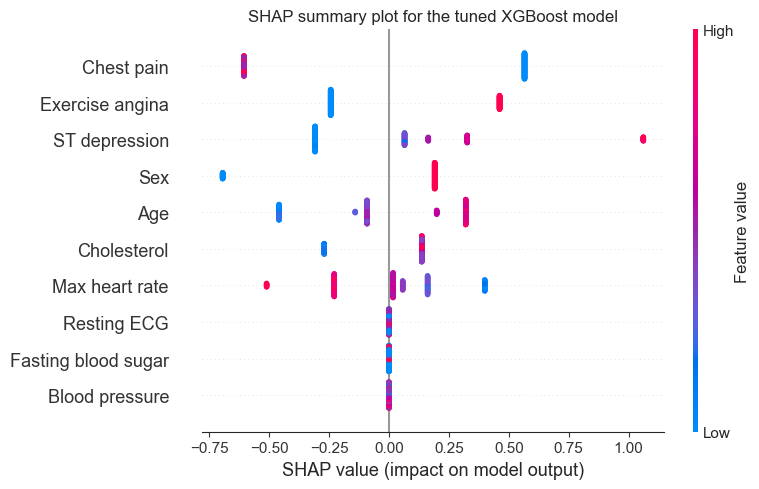

In [55]:
# Plot the global SHAP summary (beeswarm) for the tuned XGBoost model
# Each row is a feature, each dot is a patient, and the colour shows whether the feature value was high or low
shap.summary_plot(shap_values_xgb, X_test_display, plot_size=(8, 5), show=False)
plt.title('SHAP summary plot for the tuned XGBoost model')
plt.tight_layout()
plt.show()

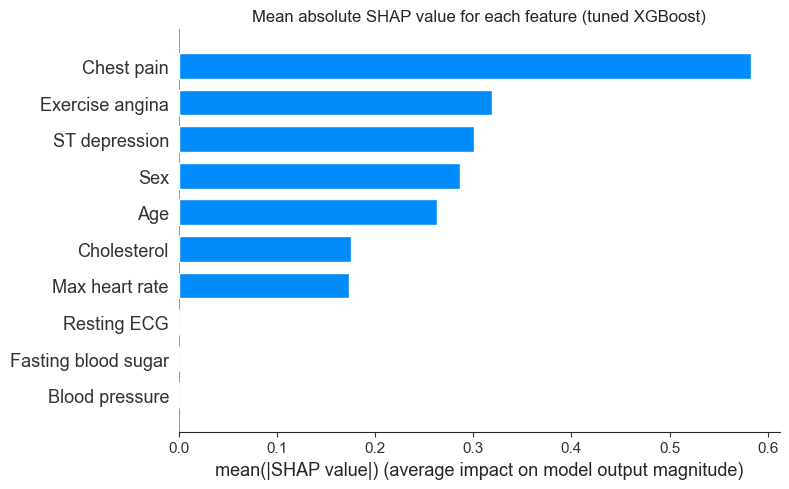

In [56]:
# Plot the mean absolute SHAP value for each feature as a bar chart
# This is a simpler ranking of overall feature importance
shap.summary_plot(shap_values_xgb, X_test_display, plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (tuned XGBoost)')
plt.tight_layout()
plt.show()

The two plots agree on which features the model relies on most. Chest pain is by far the strongest driver, followed by exercise angina and ST depression, with sex the fourth most important feature. Age, cholesterol and maximum heart rate sit in the middle, while resting ECG, fasting blood sugar and blood pressure contribute the least. This ordering is close to the univariate feature ranking seen earlier, where chest pain, exercise angina and ST depression also stood out, which is reassuring: the model relies on the same clinically meaningful features that the simple statistical tests highlighted.

The summary plot adds the direction of each effect. For the numerical features the colour reads directly, since red marks high values and blue marks low values: high ST depression and high age tend to push the prediction towards heart disease, while a high maximum heart rate tends to push it away in this model. The categorical features were converted to numbers during preprocessing, so their colours follow the encoding rather than a natural scale. Sex is encoded as Male=1 and Female=0, so the red points are male patients and the blue points are female patients, and the two colours sit on opposite sides of zero, which shows that the model uses sex in opposite directions for the two groups. Chest pain and exercise angina are encoded in the same way, so their colours should be read as category codes rather than as high or low amounts.

Sex being the fourth most important feature, and pushing the prediction in opposite directions for male and female patients, is the first sign that the model treats the two sexes differently. This is examined in detail later in the gender-stratified analysis.

One caveat applies to all of these readings. SHAP shows how the model uses each feature, not what causes heart disease, so a high SHAP value for a feature means the model relied on it, not that the feature is a clinical cause. The values are also computed under an assumption of feature independence, so for the clinical features that are mildly correlated the attributions should be read as a guide to the model's behaviour rather than as exact quantities.

### Local SHAP

Global SHAP showed which features matter across all patients, but a clinician treating one person needs to know why the model reached its decision for that specific patient. Local SHAP answers this by explaining a single prediction: it shows, for one patient, how each feature pushed the predicted risk up or down, starting from the base value (the average prediction across the data) and ending at the final prediction for that patient. This is the case-level explanation a doctor would need to decide whether to trust and act on the model's output.

The explanation is shown with a waterfall plot, which lists the features for one patient from the most influential at the top to the least at the bottom. Each bar shows how much that feature moved the prediction: red bars push the prediction towards heart disease and blue bars push it away. Two patients are shown for contrast, one the model predicts has heart disease and one it predicts is healthy, so the difference in how the features behave can be seen directly.

In [57]:
# Build a separate explainer for the local explanations, which return the SHAP values together with the feature values for each patient
# The training data is used as the background, with all 736 training patients and readable feature names for the plots
X_train_display = X_train_df.rename(columns=readable_labels)
masker = shap.maskers.Independent(X_train_display, max_samples=736)
local_explainer_xgb = shap.Explainer(tuned_xgb, masker)

# Compute the local explanations for the test set patients, using the same readable names
local_shap_xgb = local_explainer_xgb(X_test_display)

# Confirm the explanation has one entry per patient with the base value and the per-feature contributions
print('Local explanations computed for the tuned XGBoost model')
print('Number of patients explained: {}'.format(local_shap_xgb.shape[0]))
print('Number of features per patient: {}'.format(local_shap_xgb.shape[1]))

Local explanations computed for the tuned XGBoost model
Number of patients explained: 184
Number of features per patient: 10


Patient 144: actual = 1, predicted probability of disease = 0.953


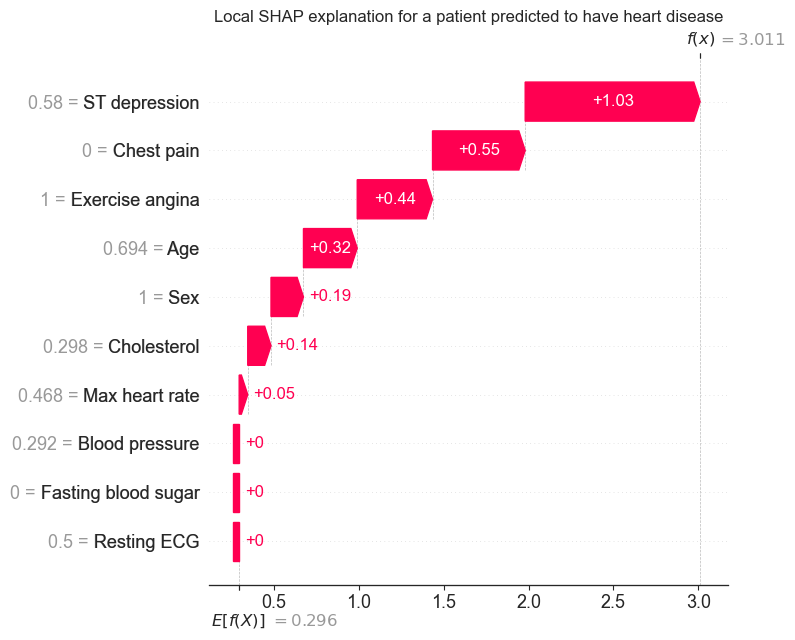

In [58]:
# Pick the patient with the highest and the lowest predicted probability of disease
probabilities = tuned_xgb.predict_proba(X_test_df)[:, 1]
patient_with_disease = probabilities.argmax()
patient_without_disease = probabilities.argmin()

# Explain the patient the model predicts has heart disease
print('Patient {}: actual = {}, predicted probability of disease = {:.3f}'
      .format(patient_with_disease, y_test.values[patient_with_disease],
              probabilities[patient_with_disease]))

shap.plots.waterfall(local_shap_xgb[patient_with_disease], show=False)
plt.title('Local SHAP explanation for a patient predicted to have heart disease')
plt.tight_layout()
plt.show()

Patient 29: actual = 0, predicted probability of disease = 0.070


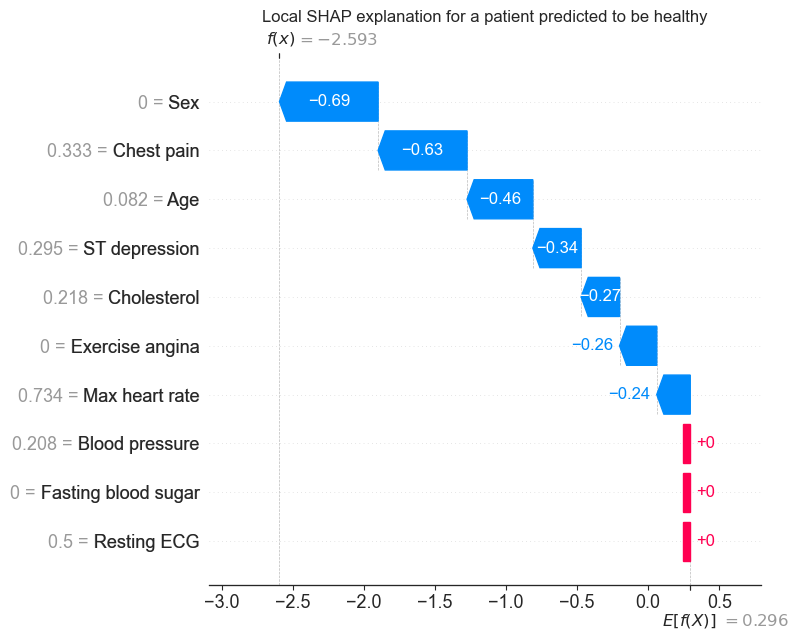

In [59]:
# Explain the patient the model predicts is healthy, for contrast
print('Patient {}: actual = {}, predicted probability of disease = {:.3f}'
      .format(patient_without_disease, y_test.values[patient_without_disease],
              probabilities[patient_without_disease]))

shap.plots.waterfall(local_shap_xgb[patient_without_disease], show=False)
plt.title('Local SHAP explanation for a patient predicted to be healthy')
plt.tight_layout()
plt.show()

The two waterfall plots are read from the base value at the bottom, which is the average prediction across the training patients (0.296 in log-odds), up to the model's output for that patient. The two cases chosen are the ones the model was most confident about, so the contrast between them is clear.

For the patient predicted to have heart disease, every feature pushes the prediction towards disease (all bars are red), taking the output from the base value up to 3.011. ST depression is the strongest push (+1.03), followed by chest pain (+0.55), exercise angina (+0.44) and age (+0.32). For the patient predicted to be healthy, the features push the other way (the bars are blue), taking the output down to -2.593, with sex (-0.69), chest pain (-0.63) and age (-0.46) being the strongest. The same features therefore act in opposite directions for these two patients, which is exactly what a local explanation is meant to show: how the model reached its decision for one individual rather than on average.

Sex behaves differently for the two patients. For the male patient it pushes the prediction slightly towards disease (+0.19), while for the female patient it is the single strongest push away from disease (-0.69). This echoes the global finding that the model uses sex in opposite directions for the two groups, and it is examined directly in the gender-stratified analysis next. As before, these readings describe how the model used each feature for these patients, not a clinical cause of heart disease.

### Gender-stratified SHAP

The global and local analyses showed that sex is one of the features the model relies on. This section looks at that more directly by computing SHAP separately for female and male patients, to see whether the model uses the features differently for the two groups. A difference in how a feature is used across the sexes is a possible source of the bias examined in the fairness analysis later.

The same SHAP values from the global analysis are split into the female and male patients, and a mean absolute SHAP bar plot is produced for each group. Comparing the two rankings shows whether any feature, in particular sex itself, carries a different weight for female and male patients. The female group is smaller (35 patients against 149), so its ranking is based on fewer cases and is read with that in mind.

In [60]:
# Split the test set patients into female and male using the encoded sex column
female_mask = X_test_df['sex'] == 0
male_mask = X_test_df['sex'] == 1

# Take the SHAP values for each group separately, using the same values computed for the global analysis
female_shap_xgb = shap_values_xgb[female_mask.values]
male_shap_xgb = shap_values_xgb[male_mask.values]

# Confirm how many patients fall into each group
print('Female patients in the test set: {}'.format(female_mask.sum()))
print('Male patients in the test set: {}'.format(male_mask.sum()))
print('Shape of female SHAP values: {}'.format(female_shap_xgb.shape))
print('Shape of male SHAP values: {}'.format(male_shap_xgb.shape))

Female patients in the test set: 35
Male patients in the test set: 149
Shape of female SHAP values: (35, 10)
Shape of male SHAP values: (149, 10)


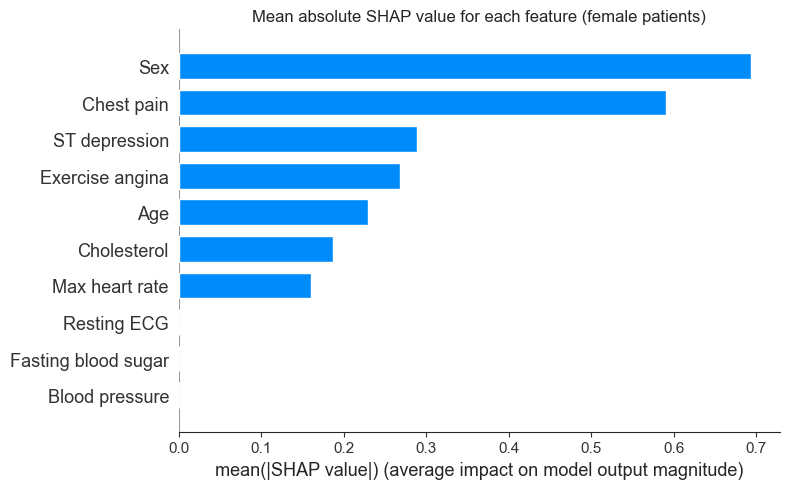

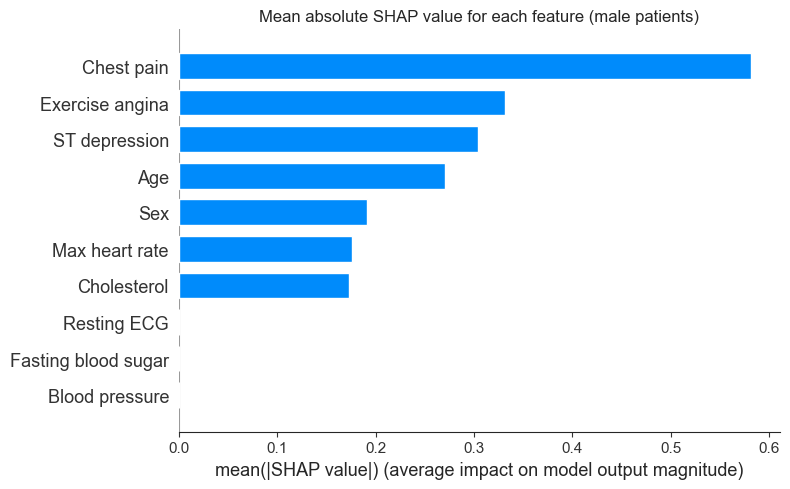

In [61]:
# Plot the mean absolute SHAP value for each feature for the female patients only
shap.summary_plot(female_shap_xgb, X_test_display[female_mask.values], plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (female patients)')
plt.tight_layout()
plt.show()

# Plot the same for the male patients only, so the two rankings can be compared
shap.summary_plot(male_shap_xgb, X_test_display[male_mask.values], plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (male patients)')
plt.tight_layout()
plt.show()

In [62]:
# Take the SHAP values for the sex feature only, for each group, keeping the sign to show direction
female_sex_shap_xgb = pd.DataFrame(female_shap_xgb, columns=X.columns)['sex']
male_sex_shap_xgb = pd.DataFrame(male_shap_xgb, columns=X.columns)['sex']

# A negative value pushes towards no disease, a positive value towards disease
print('Mean SHAP for sex, female patients: {:.4f}'.format(female_sex_shap_xgb.mean()))
print('Mean SHAP for sex, male patients: {:.4f}'.format(male_sex_shap_xgb.mean()))

Mean SHAP for sex, female patients: -0.6941
Mean SHAP for sex, male patients: 0.1909


The two bar plots show that the model relies on the features differently for the two sexes. For female patients sex is the single most important feature, ahead of chest pain, while for male patients sex drops to fifth place behind chest pain, exercise angina, ST depression and age. The clinical features lead the ranking for men, but for women sex itself carries the most weight.

The direction of the sex effect confirms this. Averaged across each group, the mean SHAP value for sex is -0.6941 for female patients and +0.1909 for male patients. The two signs are opposite: being female pushes the prediction towards no disease, while being male pushes it towards disease. The effect is also far stronger for women, since the size of the female value is about three and a half times the male one, which matches sex being the top feature for women but a minor one for men.

This is the clearest sign so far that the model treats the two sexes differently. It relies on the clinical measurements to assess male patients, but leans heavily on sex itself when assessing female patients, pushing them towards a no-disease prediction. A model that pushes female patients towards no disease in this way could miss real cases, which is the pattern of under-diagnosis reported for women in the clinical literature. As with the earlier SHAP results, this describes how the model uses sex, not a clinical cause, and the female ranking is based on the smaller group of 35 patients, so it is read as a strong indication rather than an exact measurement.

### LIME

SHAP explained the predictions using a single, theoretically grounded method. LIME (Local Interpretable Model-agnostic Explanations) is used here as a second, independent check on those local explanations. It works in a completely different way: instead of using game theory, it slightly changes the patient's feature values many times, watches how the prediction reacts, and fits a simple linear model around that one patient to see which features mattered most. If LIME points to the same features as SHAP for the same patient, that agreement gives more confidence that the explanation reflects the model rather than the quirks of one method.

The same two patients explained with SHAP are used again, the one the model is most confident has heart disease and the one it is most confident is healthy, so the two tools can be compared directly on the same cases.

In [63]:
# Import the LIME library for explaining individual predictions
import lime
import lime.lime_tabular

# The categorical columns are given to LIME by their index so it does not treat them as continuous
# sex, cp, fbs, restecg and exang are at positions 1, 2, 5, 6 and 8
categorical_features = [1, 2, 5, 6, 8]

# Build the LIME explainer on the training data, with the readable feature names used for the SHAP plots and class labels
# The random state is fixed so the explanations are reproducible
lime_explainer = lime.lime_tabular.LimeTabularExplainer(X_train, mode='classification',
                                                        feature_names=X_test_display.columns.tolist(),
                                                        categorical_features=categorical_features,
                                                        class_names=['No disease', 'Disease'],
                                                        random_state=random_state)

LIME explanation for the patient predicted to have heart disease (patient 144)


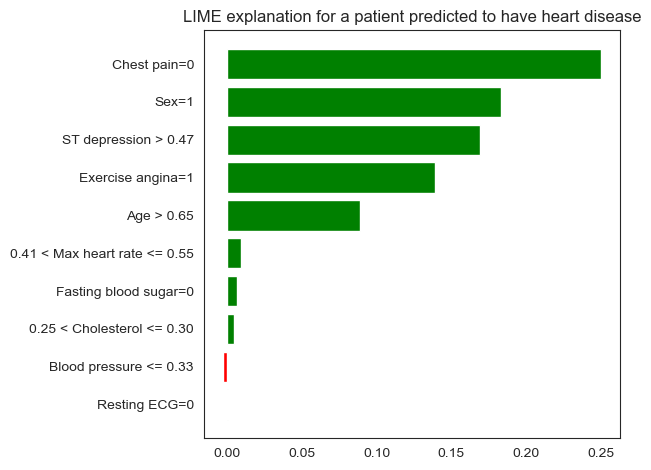

In [64]:
# Explain the same two patients used for the local SHAP analysis, found earlier with argmax and argmin
# Explain the patient predicted to have heart disease, asking LIME for all ten features
exp_disease = lime_explainer.explain_instance(X_test[patient_with_disease], tuned_xgb.predict_proba, num_features=10)
print('LIME explanation for the patient predicted to have heart disease (patient {})'.format(patient_with_disease))

# Show the explanation as a bar chart, where each bar is a feature pushing the prediction towards disease or no disease
exp_disease.as_pyplot_figure()
plt.title('LIME explanation for a patient predicted to have heart disease')
plt.tight_layout()
plt.show()

LIME explanation for the patient predicted to be healthy (patient 29)


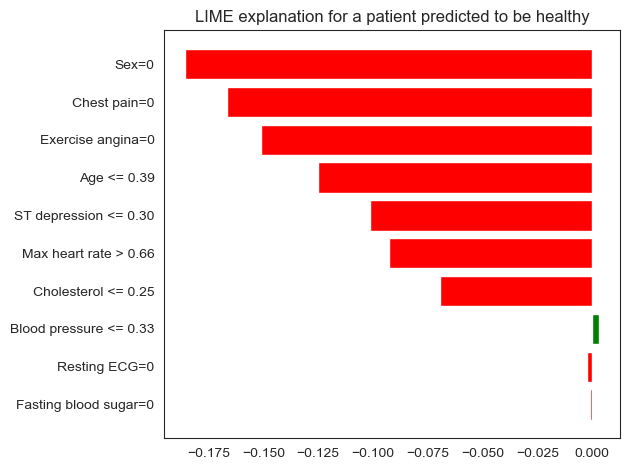

In [65]:
# Explain the patient predicted to be healthy, for contrast, again asking LIME for all ten features
exp_healthy = lime_explainer.explain_instance(X_test[patient_without_disease], tuned_xgb.predict_proba, num_features=10)
print('LIME explanation for the patient predicted to be healthy (patient {})'.format(patient_without_disease))

# Show the explanation as a bar chart, where each bar is a feature pushing the prediction towards disease or no disease
exp_healthy.as_pyplot_figure()
plt.title('LIME explanation for a patient predicted to be healthy')
plt.tight_layout()
plt.show()

The LIME results broadly agree with SHAP on which features matter, while differing in their exact order. For the patient predicted to have heart disease, LIME highlights chest pain, sex, ST depression, exercise angina and age as the main features pushing the prediction towards disease, which is the same group of features SHAP found, even though SHAP placed ST depression first and LIME placed chest pain first. For the patient predicted to be healthy, the agreement is closer: both methods put sex as the single strongest feature pushing the prediction towards no disease, followed by chest pain and age. The fact that sex comes top for the healthy female patient under both methods reinforces the gender-stratified finding rather than depending on one tool.

Some difference between the two methods is expected and does not undermine the explanations. SHAP and LIME belong to the same family of additive feature-attribution methods, but they compute their values differently: SHAP uses the exact game-theoretic Shapley values, while LIME fits a simple linear model in the local neighbourhood of the patient and so produces an approximation that depends on its sampling and on how it treats each feature. This is why the two can rank features in a slightly different order, and why LIME ranks sex higher for the male patient (second) than SHAP does (fifth). For this reason SHAP is treated as the main explainability method in this project and LIME as a supporting check: where the two agree, as they do on the leading features and on the role of sex, the explanation is more trustworthy because it does not rely on the assumptions of a single method.

### Comparing with Random Forest

All of the explanations so far have used the tuned XGBoost, the main model of this study. A natural question is whether the patterns found, in particular the way sex is used differently for female and male patients, come from the data itself or are specific to XGBoost. To check this, the same SHAP analysis is repeated for the tuned Random Forest, the second tree-based model. If a different model trained on the same data shows the same pattern, that points to the pattern being a property of the data rather than of one algorithm.

Random Forest is also tree-based, so the same TreeExplainer is used to compute its SHAP values. The global ranking and the gender-stratified comparison are produced for the Random Forest and placed next to the XGBoost results, which is enough to see whether the two models rely on sex in the same way.

In [66]:
# Build a TreeExplainer for the tuned Random Forest, which is also tree-based
explainer_rf = shap.TreeExplainer(tuned_rf)

# Compute the SHAP values, keeping the disease class (index 1) since a scikit-learn classifier returns both classes
shap_values_rf = explainer_rf.shap_values(X_test_df)[:, :, 1]

# Confirm the shape: one value per patient per feature, for the disease class
print('SHAP values computed for the tuned Random Forest model')
print('Shape of the SHAP values: {}'.format(shap_values_rf.shape))
print('This is {} patients and {} features'.format(shap_values_rf.shape[0], shap_values_rf.shape[1]))

SHAP values computed for the tuned Random Forest model
Shape of the SHAP values: (184, 10)
This is 184 patients and 10 features


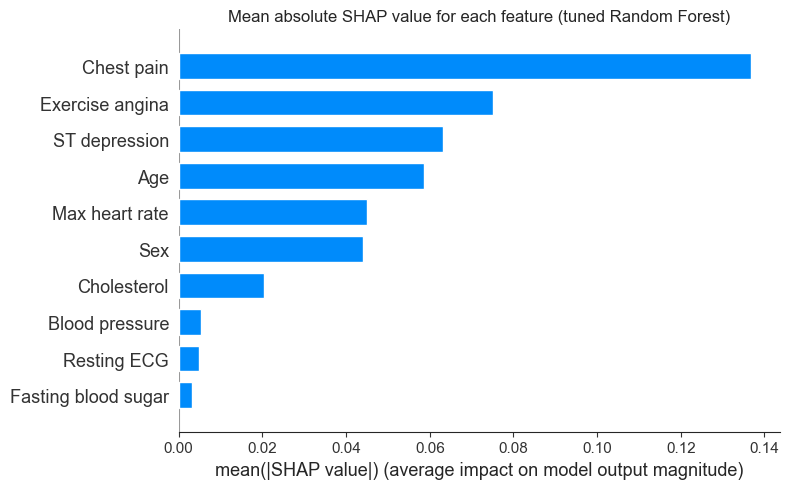

In [67]:
# Plot the mean absolute SHAP value for each feature for the Random Forest, to compare its ranking with XGBoost
shap.summary_plot(shap_values_rf, X_test_display, plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (tuned Random Forest)')
plt.tight_layout()
plt.show()

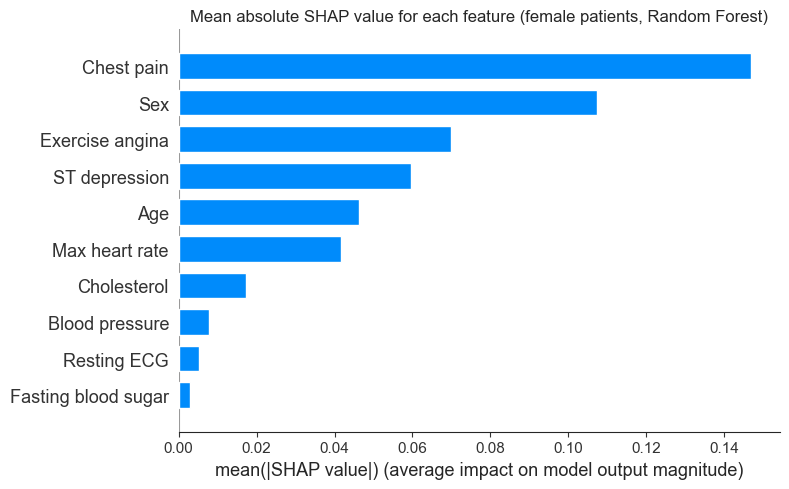

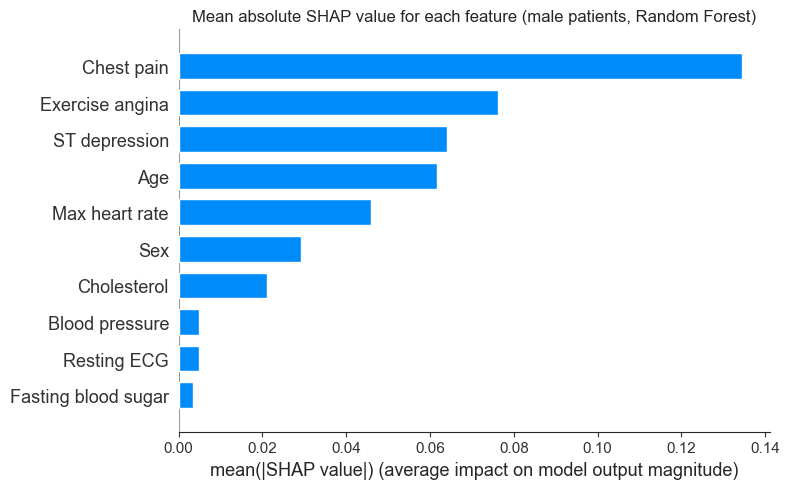

In [68]:
# Split the Random Forest SHAP values into female and male, using the same masks as before
female_shap_rf = shap_values_rf[female_mask.values]
male_shap_rf = shap_values_rf[male_mask.values]

# Plot the mean absolute SHAP value for each feature for the female patients only
shap.summary_plot(female_shap_rf, X_test_display[female_mask.values], plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (female patients, Random Forest)')
plt.tight_layout()
plt.show()

# Plot the same for the male patients only, so the two rankings can be compared
shap.summary_plot(male_shap_rf, X_test_display[male_mask.values], plot_type='bar', plot_size=(8, 5), show=False)
plt.title('Mean absolute SHAP value for each feature (male patients, Random Forest)')
plt.tight_layout()
plt.show()

In [69]:
# Take the Random Forest SHAP values for the sex feature only, for each group, keeping the sign to show direction
female_sex_shap_rf = pd.DataFrame(female_shap_rf, columns=X.columns)['sex']
male_sex_shap_rf = pd.DataFrame(male_shap_rf, columns=X.columns)['sex']

# A negative value pushes towards no disease, a positive value towards disease
print('Mean SHAP for sex, female patients (Random Forest): {:.4f}'.format(female_sex_shap_rf.mean()))
print('Mean SHAP for sex, male patients (Random Forest): {:.4f}'.format(male_sex_shap_rf.mean()))

Mean SHAP for sex, female patients (Random Forest): -0.1074
Mean SHAP for sex, male patients (Random Forest): 0.0292


The Random Forest shows the same pattern as XGBoost. In its global ranking the leading features are the same, with chest pain, exercise angina and ST depression at the top. More importantly, the gender-stratified comparison repeats the XGBoost finding: sex is one of the most important features for female patients (second, just behind chest pain), but drops well down the ranking for male patients (sixth). The direction is also the same, with a mean SHAP for sex of -0.1074 for female patients and +0.0292 for male patients, so being female pushes the prediction towards no disease while being male pushes it slightly towards disease, and the effect is again far stronger for women.

The size of the Random Forest values is smaller than the XGBoost ones, but this is expected and not meaningful on its own, because the two models report their output on different scales. What matters is that the shape of the result is the same: both models lean on sex far more for female patients than for male patients, and in the same direction. Because two different models, one boosting and one bagging, trained on the same data produce the same pattern, the recurrence of the pattern across both model families suggests it is not specific to one algorithm. This strengthens the earlier finding that the way sex is used recurs across this dataset, which is what the fairness analysis examines next.

## 8. Fairness Analysis

The explainability analysis showed that the model uses sex differently for female and male patients. This section measures whether that difference translates into unfair outcomes, by comparing the model's behaviour for the two groups across five fairness metrics. The analysis focuses on the tuned XGBoost first, then summarises all three models.

A model can be accurate overall while still treating two groups differently. To capture this, the predictions are split by sex and the following are compared between female and male patients: the basic error rates (false negative and false positive rate), and five fairness metrics. The false negative rate matters most clinically, since a false negative means a patient who truly has heart disease is predicted healthy, so a higher false negative rate for one sex means that group's real cases are missed more often.

The five fairness metrics each capture a different idea of fairness:
- **Demographic parity** asks whether the model predicts disease at the same rate for both sexes.
- **Equalised odds** asks whether the true positive and false positive rates are the same for both sexes.
- **Predictive parity** asks whether a positive prediction is equally trustworthy for both sexes (equal precision).
- **Disparate impact** is the ratio of the two positive-prediction rates, where a ratio of 1 indicates equal positive-prediction rates and 0.8 is the four-fifths reference threshold.
- **Calibration** asks whether a predicted probability means the same thing for both sexes.

These metrics cannot all be satisfied at once when the two groups have different base rates, which is the case here (the disease rate is 63.22% for male patients and 25.77% for female patients). This is the impossibility result that the project sets out to present rather than solve: improving one metric tends to worsen another, and the analysis below shows which trade-offs appear in this dataset.

In [70]:
# Import the fairness metrics from Fairlearn and the calibration tools from scikit-learn
from fairlearn.metrics import MetricFrame, false_negative_rate, false_positive_rate, true_positive_rate, true_negative_rate, selection_rate
from fairlearn.metrics import demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference
from sklearn.calibration import calibration_curve

In [71]:
# Map the encoded sex column to readable labels so the fairness metrics are grouped clearly
sex_labels = X_test_df['sex'].map({0: 'Female', 1: 'Male'})

# Confirm the sex labels match the expected counts from the test set
print('Sex label counts in the test set:\n{}'.format(sex_labels.value_counts()))

Sex label counts in the test set:
sex
Male      149
Female     35
Name: count, dtype: int64


### Performance by sex

Before computing the formal fairness metrics, the basic performance of the tuned XGBoost is compared between female and male patients. The recall (true positive rate) shows how many real disease cases the model catches in each group, and the false negative rate shows the share of real cases it misses. A higher false negative rate for one sex would mean that group's true cases are missed more often, which is the concern raised by the gender-stratified explanation earlier. Precision and the false positive rate are shown alongside to give the full picture.

In [72]:
# Compare the basic performance of the tuned XGBoost between female and male patients
# A dictionary of metrics is passed so MetricFrame returns one row per sex for each metric
performance_metrics = {'Recall': recall_score, 'Precision': precision_score, 'False negative rate': false_negative_rate, 'False positive rate': false_positive_rate}

# MetricFrame splits the predictions by sex and computes each metric separately for each group
performance_by_sex = MetricFrame(metrics=performance_metrics,
                                 y_true=y_test,
                                 y_pred=tuned_xgb_pred,
                                 sensitive_features=sex_labels)

# Show the metrics for each sex side by side
print('Performance by sex for the tuned XGBoost:\n{}'.format(performance_by_sex.by_group.round(4)))

Performance by sex for the tuned XGBoost:
        Recall  Precision  False negative rate  False positive rate
sex                                                                
Female   0.625      0.625                0.375               0.1111
Male     0.883      0.830                0.117               0.3091


The performance differs sharply between the two groups. The false negative rate is 0.3750 for female patients but only 0.1170 for male patients, so the model misses a far larger share of real disease cases in women: roughly one in three female patients who truly have heart disease is predicted healthy, against about one in nine male patients. The recall figures show the same gap from the other side, with the model catching 0.6250 of true cases in women against 0.8830 in men. This is the concern raised by the gender-stratified explanation now seen in the outcomes: the model leans on sex to push female patients towards a no-disease prediction, and here that shows up as real cases being missed more often for women.

The false positive rate runs the other way, higher for male patients (0.3091) than female patients (0.1111), so men are more often flagged when they are healthy. This opposite pattern in the two error rates is an early sign of the trade-off examined below: the false negative and false positive rates cannot both be balanced across the sexes at the same time.

These figures should be read with the size of the female group in mind. There are only 35 female patients in the test set, and the false negative rate is calculated over the smaller number of those who truly have disease, so the exact values are based on few patients. The direction is clear and consistent with the explainability results, but the precise values are best treated as a strong indication rather than an exact measurement.

### The five fairness metrics

The five fairness metrics are now computed for the tuned XGBoost. Four of them are reported as a single number summarising the gap between the two sexes. Demographic parity, equalised odds and disparate impact use the Fairlearn functions directly. Predictive parity has no direct function, so it is computed as the difference in precision between the two groups, taken from the per-sex precision already seen above. For the difference metrics a value of 0 means the two sexes are treated identically, while for disparate impact a ratio of 1 means identical treatment and 0.8 is the four-fifths reference threshold. Calibration is handled separately afterwards.

In [73]:
# Compute the four threshold-based fairness metrics for the tuned XGBoost
# Demographic parity, equalised odds and disparate impact have direct Fairlearn functions
dp_difference = demographic_parity_difference(y_test, tuned_xgb_pred, sensitive_features=sex_labels)
eo_difference = equalized_odds_difference(y_test, tuned_xgb_pred, sensitive_features=sex_labels)
di_ratio = demographic_parity_ratio(y_test, tuned_xgb_pred, sensitive_features=sex_labels)

# Predictive parity has no direct function, so it is the difference in precision between the two groups
precision_by_sex = MetricFrame(metrics=precision_score,
                               y_true=y_test,
                               y_pred=tuned_xgb_pred,
                               sensitive_features=sex_labels)
pp_difference = precision_by_sex.difference()

# Print the four metrics together
print('Demographic parity difference: {:.4f}'.format(dp_difference))
print('Equalised odds difference: {:.4f}'.format(eo_difference))
print('Predictive parity difference: {:.4f}'.format(pp_difference))
print('Disparate impact ratio: {:.4f}'.format(di_ratio))

Demographic parity difference: 0.4426
Equalised odds difference: 0.2580
Predictive parity difference: 0.2050
Disparate impact ratio: 0.3406


All four metrics show a clear gap between the two sexes. The demographic parity difference is 0.4426, meaning the model predicts disease at very different rates for women and men, which follows directly from the large base rate difference seen earlier. The disparate impact ratio is the most striking: at 0.3406 it falls far below the 0.8 threshold of the four-fifths rule, so women are flagged as having disease at only about a third of the rate of men. The equalised odds difference of 0.2580 reflects the gap in recall already seen, since the model catches far fewer of the true cases in women, and the predictive parity difference of 0.2050 matches the precision gap between the groups.

The important point is that all four metrics are violated at the same time. This is not a coincidence but the expected consequence of the two sexes having very different base rates: when base rates differ, these metrics cannot all be satisfied together, so a model that is unfair on one will tend to be unfair on the others as well. This is the impossibility result at the centre of the project. The metrics above are the starting point, not something to be fixed; the mitigation section later shows what happens when one of them is forced towards zero, and which of the others worsens as a result.

### Calibration by sex

The final fairness metric is calibration, which asks whether a predicted probability means the same thing for both sexes. A model is well calibrated if, among patients given a predicted risk of around 0.7, about 70% truly have heart disease, and this should hold equally for women and men. Calibration is shown here with a reliability diagram, where the predicted probability is plotted against the observed proportion of real cases in each bin, separately for each sex. A curve close to the diagonal means the predicted probabilities can be trusted, while a curve below the diagonal means the model overestimates risk and a curve above means it underestimates. The female group is small at 35 patients, so its curve is based on few cases and is best read for its general direction rather than its exact shape.

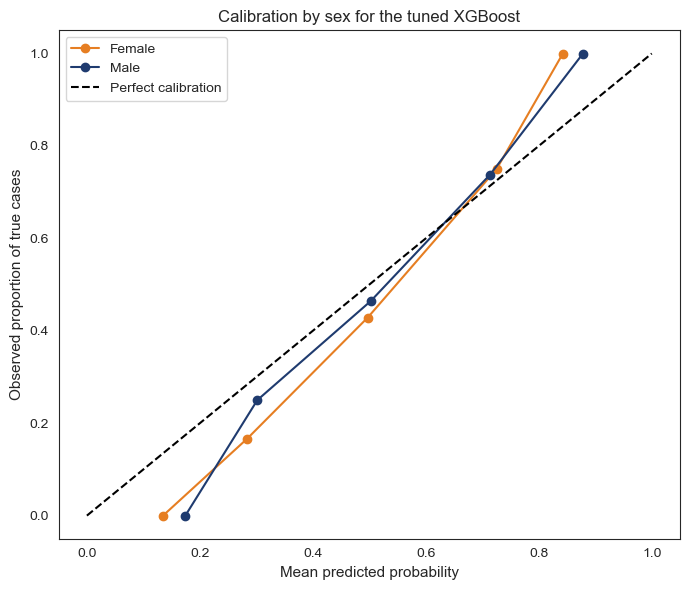

In [74]:
# Assess calibration separately for female and male patients using a reliability diagram
tuned_xgb_proba = tuned_xgb.predict_proba(X_test)[:, 1]

# Compute the calibration curve for each sex, using the same masks as the gender analysis
female_prob_true, female_prob_pred = calibration_curve(y_test[female_mask.values], tuned_xgb_proba[female_mask.values], n_bins=5)
male_prob_true, male_prob_pred = calibration_curve(y_test[male_mask.values], tuned_xgb_proba[male_mask.values], n_bins=5)

# Plot the two reliability curves together with the diagonal line for perfect calibration
plt.figure(figsize=(7, 6))
plt.plot(female_prob_pred, female_prob_true, marker='o', color='#e67e22', label='Female')
plt.plot(male_prob_pred, male_prob_true, marker='o', color='#1f3b6f', label='Male')
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect calibration')
plt.title('Calibration by sex for the tuned XGBoost')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion of true cases')
plt.legend()
plt.tight_layout()
plt.show()

For both sexes the curve sits below the diagonal at the lower predicted risks and moves above it at the higher predicted risks, rather than staying on one side. This means that for patients given a low predicted risk the model tends to overestimate the chance of disease, while for patients given a high predicted risk it tends to underestimate it, so the predicted probabilities are pulled towards the middle. The female and male curves follow a broadly similar shape, with the female curve resting a little lower in the middle range, so the overestimation at low risks is slightly stronger for women.

Unlike the earlier metrics, calibration does not show a sharp split between the sexes. The two groups follow a similar pattern, which is itself worth noting: a model can be clearly unfair on the threshold-based metrics while still assigning probabilities that behave in much the same way for both groups. As before, the female curve rests on only 35 patients, so its exact path should be read with caution and taken as a general direction rather than a precise measurement.

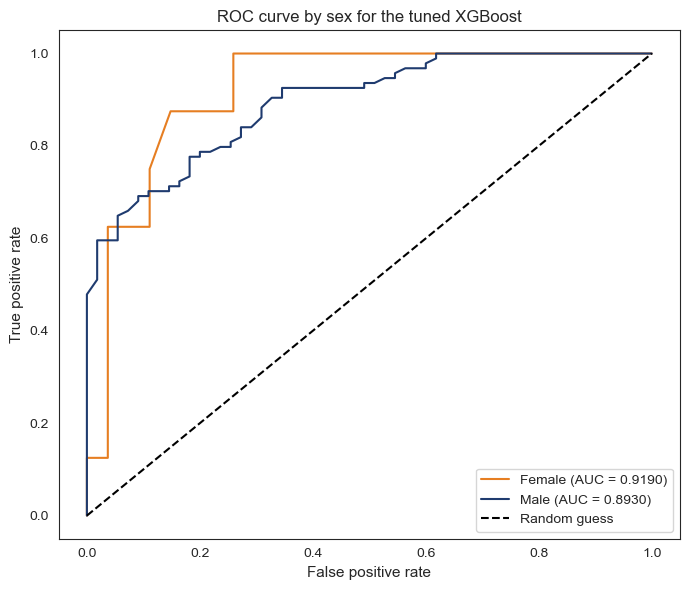

In [75]:
# Plot the ROC curve separately for female and male patients to visualise the equalised odds gap
female_fpr, female_tpr, _ = roc_curve(y_test[female_mask.values], tuned_xgb_proba[female_mask.values])
male_fpr, male_tpr, _ = roc_curve(y_test[male_mask.values], tuned_xgb_proba[male_mask.values])

# Plot both curves together with the diagonal line for a model with no predictive ability
plt.figure(figsize=(7, 6))
plt.plot(female_fpr, female_tpr, label='Female (AUC = {:.4f})'.format(roc_auc_score(y_test[female_mask.values], tuned_xgb_proba[female_mask.values])), color='#e67e22')
plt.plot(male_fpr, male_tpr, label='Male (AUC = {:.4f})'.format(roc_auc_score(y_test[male_mask.values], tuned_xgb_proba[male_mask.values])), color='#1f3b6f')
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Random guess')
plt.title('ROC curve by sex for the tuned XGBoost')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.tight_layout()
plt.show()

The two curves describe how well the model separates disease cases from healthy patients across every possible threshold, drawn separately for each sex. The area under the female curve is slightly higher than the male one, which means that across thresholds the model ranks female patients at least as well as male patients, so the gap seen earlier is not caused by the model being unable to tell female cases apart. The two curves do not lie on top of each other, however, and they pull away from each other in the lower range of the false positive rate, which is the region where the default threshold operates.

This connects the ROC picture to the earlier finding. The model can rank female patients well, yet at the fixed threshold used for the predictions it still misses a larger share of true female cases, so the problem is less about the model's ability to separate the classes and more about where the single shared threshold falls for each group. Two separate curves mean the true positive and false positive rates differ across thresholds, which is consistent with the equalised odds gap measured before, and they point towards adjusting the decision threshold per group rather than retraining the model, which is taken up in the mitigation section. The female curve is built from only 35 patients, so it is less smooth and its exact shape should be read with that in mind.

### What the fairness analysis shows for the tuned XGBoost

Taken together, the results show a consistent gap between the sexes on the threshold-based measures. The model selects the disease class far less often for women, misses a much larger share of true female cases than male cases, and the disparate impact ratio sits well under the common 0.8 threshold, while demographic parity, equalised odds and predictive parity all show sizeable differences. Calibration is the exception: the predicted probabilities behave in a broadly similar way for both groups, which means the model is not simply assigning women systematically wrong probabilities, yet it still treats them differently once a single decision threshold is applied.

This pattern is what the impossibility results lead one to expect. The disease base rate is far higher for men than for women in this dataset, and when the base rates differ a model cannot match every fairness measure at once, so improving one tends to come at the cost of another. The clinical weight falls on the missed female cases, since a false negative means a patient with disease is told they are clear. The ROC curves add that the model can in fact rank female patients well, so the gap is tied to where the shared threshold falls rather than to the model being unable to separate the classes, which points towards threshold-based mitigation. The aim of this section is to surface these trade-offs rather than to resolve them, and they are read against the small female test group of 35 patients.

### Fairness across the three models

The fairness analysis so far has focused on the tuned XGBoost as the main model. To check whether the gap between the sexes is a property of one model or of the data itself, the four threshold-based metrics are now computed for all three tuned models side by side. Calibration is left out of this table because it is read from a curve rather than reduced to a single number, and it was already examined for the main model above. If the gap appears for every model, that points to the data rather than to a single algorithm.

In [76]:
# Compute the four threshold-based fairness metrics for each tuned model on the test set
# Predictive parity is taken as the difference in precision between the sexes, using a metric frame for each model
log_reg_precision_by_sex = MetricFrame(metrics=precision_score,
                                       y_true=y_test,
                                       y_pred=tuned_log_reg_pred,
                                       sensitive_features=sex_labels)
rf_precision_by_sex = MetricFrame(metrics=precision_score,
                                  y_true=y_test,
                                  y_pred=tuned_rf_pred,
                                  sensitive_features=sex_labels)
xgb_precision_by_sex = MetricFrame(metrics=precision_score,
                                   y_true=y_test,
                                   y_pred=tuned_xgb_pred,
                                   sensitive_features=sex_labels)

# Build a comparison table with the four fairness metrics for all three tuned models
fairness_comparison = pd.DataFrame({
    'Logistic Regression': [demographic_parity_difference(y_test, tuned_log_reg_pred, sensitive_features=sex_labels),
                            equalized_odds_difference(y_test, tuned_log_reg_pred, sensitive_features=sex_labels),
                            log_reg_precision_by_sex.difference(),
                            demographic_parity_ratio(y_test, tuned_log_reg_pred, sensitive_features=sex_labels)],
    'Random Forest': [demographic_parity_difference(y_test, tuned_rf_pred, sensitive_features=sex_labels),
                      equalized_odds_difference(y_test, tuned_rf_pred, sensitive_features=sex_labels),
                      rf_precision_by_sex.difference(),
                      demographic_parity_ratio(y_test, tuned_rf_pred, sensitive_features=sex_labels)],
    'XGBoost': [demographic_parity_difference(y_test, tuned_xgb_pred, sensitive_features=sex_labels),
                equalized_odds_difference(y_test, tuned_xgb_pred, sensitive_features=sex_labels),
                xgb_precision_by_sex.difference(),
                demographic_parity_ratio(y_test, tuned_xgb_pred, sensitive_features=sex_labels)]
}, index=['Demographic parity difference', 'Equalised odds difference', 'Predictive parity difference', 'Disparate impact ratio'])

# Show the fairness comparison rounded to four decimals for readability
print('Fairness comparison across the three tuned models:\n{}'.format(fairness_comparison.round(4)))

Fairness comparison across the three tuned models:
                               Logistic Regression  Random Forest  XGBoost
Demographic parity difference               0.5283         0.4123   0.4426
Equalised odds difference                   0.3630         0.2337   0.2580
Predictive parity difference                0.0200         0.1981   0.2050
Disparate impact ratio                      0.2129         0.4093   0.3406


The table shows the same pattern across all three models rather than in one of them alone. The disparate impact ratio is well below the 0.8 threshold for every model (0.2129 for Logistic Regression, 0.4093 for Random Forest and 0.3406 for XGBoost), and demographic parity, equalised odds and predictive parity show a clear gap for each as well. Because the gap recurs whether the model is a linear baseline, a bagged ensemble or a boosting method, it is better explained by the data than by any single algorithm. This agrees with the gender-stratified SHAP results, where two different models leaned on sex in the same way, and it points back to the large base rate difference between the sexes as the likely source.

Logistic Regression shows the trade-off between the metrics most clearly. It has by far the smallest predictive parity gap (0.0200), so a positive prediction is almost equally trustworthy for both sexes, yet at the same time it has the lowest disparate impact ratio (0.2129), so it flags women for disease least often of the three. The same model is therefore the fairest on one measure and the least fair on another, which is exactly what the impossibility result describes: when the base rates differ, being even on one fairness measure does not bring the others into line and can pull them further apart. Random Forest sits a little more evenly across the four metrics but still violates all of them.

The main point of this comparison is that choosing a different model does not remove the gap, which points back to the data rather than the algorithm. This sets up the mitigation section, where instead of swapping the model, the predictions are adjusted to reduce one metric and the effect on the others is measured. As throughout, the aim is to present these trade-offs rather than to claim any one model resolves them.

## 9. Bias Mitigation

The fairness analysis showed that the model treats the two sexes differently, and that this pattern is present in every model because it comes from the data rather than the algorithm. This section asks a different question: if the bias cannot be removed by changing the model, can it be reduced by changing the data or the decisions, and what does that cost on the other fairness metrics?

Three mitigation methods are applied, each at a different stage of the pipeline. The first two are pre-processing methods that change the training data before the model is fitted: oversampling the minority class, and reweighting the patients so that sex and the outcome are less strongly linked. The third is a post-processing method that leaves the trained model untouched and instead adjusts the decision threshold separately for each sex. In-processing methods, which change the learning algorithm itself, are outside the scope of this project.

All three methods are demonstrated on the tuned XGBoost, the main model of this study. Because the earlier analysis established that the bias is a property of the data rather than of any single model, the trade-off pattern seen here is expected to carry over to the other models as well. Each method is applied only to the training data, after the train and test split, so that the test set stays untouched and the results are not affected by leakage. After each method the same fairness metrics are measured again, so that the effect of the mitigation can be compared against the baseline. The expectation set by the impossibility result is that improving one fairness metric will tend to worsen another rather than removing the unfairness altogether.

### Oversampling with SMOTE

The first method addresses the class imbalance in the training data. In the heart disease set there are more patients with the disease than without it, and an imbalanced training set can push a model towards the majority class. SMOTE creates new synthetic patients for the minority class rather than simply copying existing ones: for each minority patient it finds its nearest neighbours of the same class and builds a new patient from them, so the added patients are plausible variations rather than exact duplicates.

Because the data has both continuous features, such as age and cholesterol, and categorical ones, such as sex and chest pain type, the SMOTE-NC variant is used, which is suited to this mix so that the categorical columns keep whole category values rather than meaningless in-between codes.

SMOTE is applied only to the training set, after the split, so that the test set still reflects the real population and the evaluation stays honest. A new XGBoost is then trained on the resampled data using the same tuned settings as before, and the fairness metrics are measured again on the untouched test set. SMOTE targets the balance between the disease classes rather than the balance between the sexes directly, so its effect on the sex-based fairness metrics is examined rather than assumed.

In [77]:
# Import SMOTE-NC, the SMOTE variant for data with both continuous and categorical features
from imblearn.over_sampling import SMOTENC

# The five categorical columns are at these positions: sex, cp, fbs, restecg and exang
# SMOTE-NC keeps these as whole categories instead of creating meaningless in-between values
categorical_indices = [1, 2, 5, 6, 8]

# Resample only the training data so that the test set stays untouched and there is no leakage
smote = SMOTENC(categorical_features=categorical_indices, random_state=random_state, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Confirm the class balance before and after resampling
print('Training class balance before SMOTE-NC:\n{}'.format(pd.Series(y_train).value_counts()))
print('\nTraining class balance after SMOTE-NC:\n{}'.format(pd.Series(y_train_smote).value_counts()))

Training class balance before SMOTE-NC:
target
1    407
0    329
Name: count, dtype: int64

Training class balance after SMOTE-NC:
target
1    407
0    407
Name: count, dtype: int64


In [78]:
# Train a new XGBoost on the resampled data, keeping the same tuned settings as before
xgb_smote = XGBClassifier(max_depth=best_xgb_depth, learning_rate=0.05, n_estimators=150, random_state=random_state, eval_metric='logloss')
xgb_smote.fit(X_train_smote, y_train_smote)

# Predict on the untouched test set so the evaluation reflects the real population
xgb_smote_pred = xgb_smote.predict(X_test)

# Measure the same four fairness metrics as before, now after SMOTE-NC
smote_dp = demographic_parity_difference(y_test, xgb_smote_pred, sensitive_features=sex_labels)
smote_eo = equalized_odds_difference(y_test, xgb_smote_pred, sensitive_features=sex_labels)
smote_di = demographic_parity_ratio(y_test, xgb_smote_pred, sensitive_features=sex_labels)

# Predictive parity has no direct function, so it is the difference in precision between the two groups
smote_precision_by_sex = MetricFrame(metrics=precision_score,
                                     y_true=y_test,
                                     y_pred=xgb_smote_pred,
                                     sensitive_features=sex_labels)
smote_pp = smote_precision_by_sex.difference()

# Report the test performance and the fairness metrics after SMOTE-NC
print('Accuracy after SMOTE-NC: {:.4f}'.format(accuracy_score(y_test, xgb_smote_pred)))
print('Recall after SMOTE-NC: {:.4f}'.format(recall_score(y_test, xgb_smote_pred)))
print('\nDemographic parity difference: {:.4f}'.format(smote_dp))
print('Equalised odds difference: {:.4f}'.format(smote_eo))
print('Predictive parity difference: {:.4f}'.format(smote_pp))
print('Disparate impact ratio: {:.4f}'.format(smote_di))

Accuracy after SMOTE-NC: 0.8043
Recall after SMOTE-NC: 0.8137

Demographic parity difference: 0.3889
Equalised odds difference: 0.2048
Predictive parity difference: 0.2228
Disparate impact ratio: 0.3702


After SMOTE-NC three of the four metrics move towards fairness while one moves away. The demographic parity difference falls from 0.4426 to 0.3889, the equalised odds difference from 0.2580 to 0.2048, and the disparate impact ratio rises from 0.3406 to 0.3702, so women are flagged a little more often relative to men, although the ratio is still well below the 0.8 threshold. The predictive parity difference moves the other way, rising from 0.2050 to 0.2228, so a positive prediction becomes slightly less equally trustworthy across the sexes. This is the impossibility result in miniature: pushing three metrics towards equality has come at the cost of the fourth.

The size of the change is modest, which is expected here. The training set was only mildly imbalanced to begin with, with about 55% of patients having the disease, so oversampling the minority class does not move the model very far. The effect on performance is small in the same way, with test accuracy slipping from 0.8152 to 0.8043 and recall from 0.8627 to 0.8137. SMOTE-NC therefore nudges the balance metrics in the fairer direction at a small cost to precision and to overall performance, rather than removing the gap.

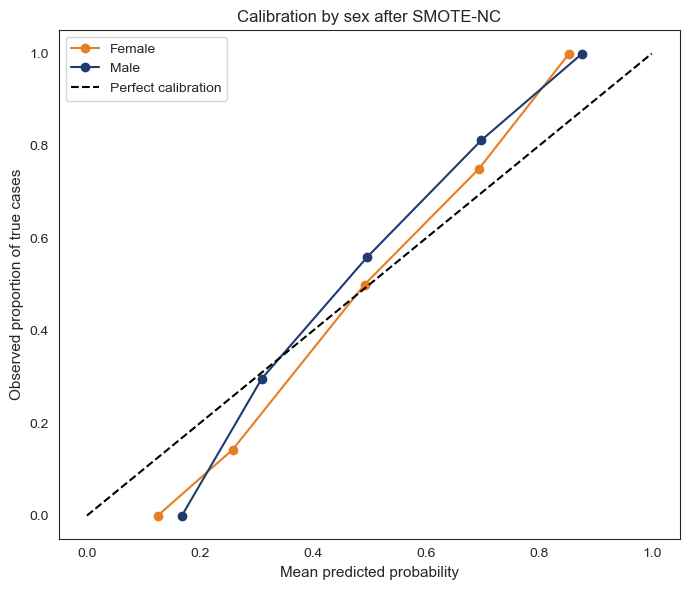

In [79]:
# Assess calibration after SMOTE-NC, using the same reliability diagram as the baseline
xgb_smote_proba = xgb_smote.predict_proba(X_test)[:, 1]

# Compute the calibration curve for each sex, using the same masks as the gender analysis
female_prob_true, female_prob_pred = calibration_curve(y_test[female_mask.values], xgb_smote_proba[female_mask.values], n_bins=5)
male_prob_true, male_prob_pred = calibration_curve(y_test[male_mask.values], xgb_smote_proba[male_mask.values], n_bins=5)

# Plot the two reliability curves together with the diagonal line for perfect calibration
plt.figure(figsize=(7, 6))
plt.plot(female_prob_pred, female_prob_true, marker='o', color='#e67e22', label='Female')
plt.plot(male_prob_pred, male_prob_true, marker='o', color='#1f3b6f', label='Male')
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect calibration')
plt.title('Calibration by sex after SMOTE-NC')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion of true cases')
plt.legend()
plt.tight_layout()
plt.show()

The calibration picture barely changes after SMOTE-NC. Both curves still sit close to each other and follow the diagonal in much the same way as the baseline, with the female curve resting a little lower in the middle range. Oversampling has therefore not introduced any new calibration gap between the sexes: the predicted probabilities still mean broadly the same thing for women and men. This matches the modest effect seen in the other metrics, since the model has changed only slightly.

### Reweighting the training data

The second method also works on the training data, but it targets the link between sex and the outcome directly rather than the balance between the disease classes. The idea is that if sex and heart disease are strongly associated in the training data, the model will learn to lean on sex, so each patient is given a weight that loosens this association before training. Patients from a sex and outcome combination that is over-represented are given a weight below one, and patients from a combination that is under-represented are given a weight above one, so that after weighting sex and the outcome look statistically independent.

The weight for each group is the rate that would be expected if sex and the outcome were independent, divided by the rate actually observed in the training data. This gives four weights, one for each combination of sex and disease status, which are then passed to the model during training. Unlike oversampling, no new patients are created and none are removed, so the same patients are used with different weights. The weighting is computed from the training data only, and the fairness metrics are then measured on the untouched test set as before.

In [80]:
# Compute a weight for each training patient so that sex and the outcome become independent
# The sex column is at index 1 in the scaled training data, with 0 for female and 1 for male
sex_train = X_train[:, 1]
n_train = len(y_train)
sample_weights = np.zeros(n_train)

# For each combination of sex and outcome, the weight is the expected rate under independence divided by the observed rate
for s in [0, 1]:
    for c in [0, 1]:
        p_sex = (sex_train == s).mean()
        p_class = (y_train.values == c).mean()
        p_joint = ((sex_train == s) & (y_train.values == c)).mean()
        group_weight = (p_sex * p_class) / p_joint
        group_mask = (sex_train == s) & (y_train.values == c)
        sample_weights[group_mask] = group_weight

# Show the four group weights to confirm the under-represented groups are weighted up
print('Weight for each sex and outcome group:')
for s in [0, 1]:
    for c in [0, 1]:
        sex_name = 'Female' if s == 0 else 'Male'
        class_name = 'no disease' if c == 0 else 'disease'
        group_mask = (sex_train == s) & (y_train.values == c)
        print('{} with {}: weight {:.4f}'.format(sex_name, class_name, sample_weights[group_mask][0]))

Weight for each sex and outcome group:
Female with no disease: weight 0.6075
Female with disease: weight 2.0935
Male with no disease: weight 1.2166
Male with disease: weight 0.8742


In [81]:
# Train a new XGBoost on the weighted training data, keeping the same tuned settings as before
xgb_reweight = XGBClassifier(max_depth=best_xgb_depth, learning_rate=0.05, n_estimators=150, random_state=random_state, eval_metric='logloss')
xgb_reweight.fit(X_train, y_train, sample_weight=sample_weights)

# Predict on the untouched test set so the evaluation reflects the real population
xgb_reweight_pred = xgb_reweight.predict(X_test)

# Measure the same four fairness metrics as before, now after reweighting
reweight_dp = demographic_parity_difference(y_test, xgb_reweight_pred, sensitive_features=sex_labels)
reweight_eo = equalized_odds_difference(y_test, xgb_reweight_pred, sensitive_features=sex_labels)
reweight_di = demographic_parity_ratio(y_test, xgb_reweight_pred, sensitive_features=sex_labels)

# Predictive parity has no direct function, so it is the difference in precision between the two groups
reweight_precision_by_sex = MetricFrame(metrics=precision_score,
                                        y_true=y_test,
                                        y_pred=xgb_reweight_pred,
                                        sensitive_features=sex_labels)
reweight_pp = reweight_precision_by_sex.difference()

# Report the test performance and the fairness metrics after reweighting
print('Accuracy after reweighting: {:.4f}'.format(accuracy_score(y_test, xgb_reweight_pred)))
print('Recall after reweighting: {:.4f}'.format(recall_score(y_test, xgb_reweight_pred)))
print('\nDemographic parity difference: {:.4f}'.format(reweight_dp))
print('Equalised odds difference: {:.4f}'.format(reweight_eo))
print('Predictive parity difference: {:.4f}'.format(reweight_pp))
print('Disparate impact ratio: {:.4f}'.format(reweight_di))

Accuracy after reweighting: 0.7880
Recall after reweighting: 0.8235

Demographic parity difference: 0.2460
Equalised odds difference: 0.0559
Predictive parity difference: 0.2985
Disparate impact ratio: 0.6016


Reweighting has a much stronger effect than oversampling, and it shows the trade-off far more sharply. Three of the four metrics improve clearly: the demographic parity difference falls from 0.4426 to 0.2460, the disparate impact ratio rises from 0.3406 to 0.6016, much closer to the 0.8 threshold, and the equalised odds difference drops from 0.2580 to 0.0559, so the gap in error rates between the sexes is almost closed. This is the expected result of a method that targets the link between sex and the outcome directly rather than the class balance.

The cost falls on predictive parity, which moves the other way and by more than under oversampling, rising from 0.2050 to 0.2985. A positive prediction is now noticeably less equally trustworthy across the sexes, even though the model treats the two groups much more evenly in terms of selection and error rates. This is the impossibility result at its clearest in the whole project: forcing the error-rate metrics towards equality has pulled predictive parity further apart, because the two cannot hold at once when the base rates differ. The effect on performance is again small, with test accuracy at 0.7880 and recall at 0.8235, so the gain in the balance metrics comes at a limited cost to overall accuracy but a real cost to predictive parity.

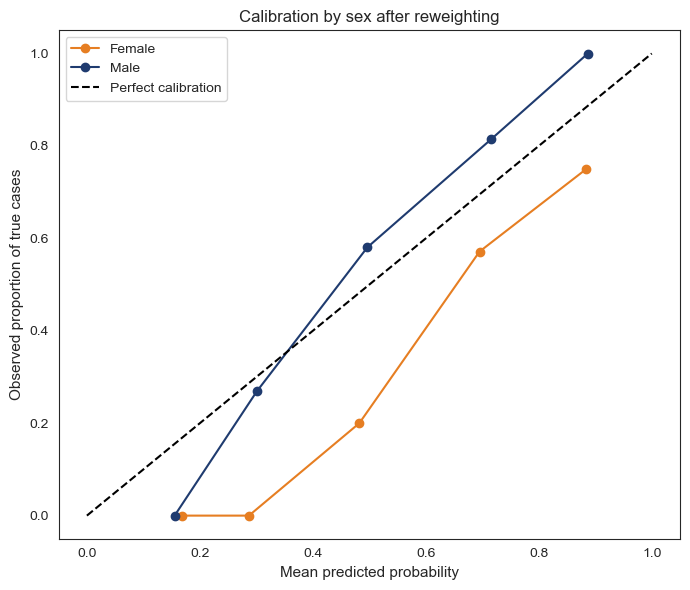

In [82]:
# Assess calibration after reweighting, using the same reliability diagram as the baseline
xgb_reweight_proba = xgb_reweight.predict_proba(X_test)[:, 1]

# Compute the calibration curve for each sex, using the same masks as the gender analysis
female_prob_true, female_prob_pred = calibration_curve(y_test[female_mask.values], xgb_reweight_proba[female_mask.values], n_bins=5)
male_prob_true, male_prob_pred = calibration_curve(y_test[male_mask.values], xgb_reweight_proba[male_mask.values], n_bins=5)

# Plot the two reliability curves together with the diagonal line for perfect calibration
plt.figure(figsize=(7, 6))
plt.plot(female_prob_pred, female_prob_true, marker='o', color='#e67e22', label='Female')
plt.plot(male_prob_pred, male_prob_true, marker='o', color='#1f3b6f', label='Male')
plt.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfect calibration')
plt.title('Calibration by sex after reweighting')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion of true cases')
plt.legend()
plt.tight_layout()
plt.show()

The calibration picture also changes, and not for the better. Unlike the baseline and the oversampled model, where the two curves stayed close together, the female curve now sits clearly below the male one and below the diagonal through the middle range, which means the model overestimates the risk of disease for women after reweighting. This follows from how the method works: giving the female disease group a much larger weight pushes the model towards predicting disease for women, so the probabilities it assigns them run higher than the true rate.

This is an important addition to the trade-off. Reweighting did not only worsen predictive parity; it also introduced a calibration gap between the sexes that was not there before. Improving the error-rate metrics has therefore come at a cost on two fronts at once, predictive parity and calibration, which is a stronger illustration of the impossibility result than any single metric on its own. It also shows why calibration is worth checking at each stage rather than assuming a fairer-looking model is fairer in every sense.

### Adjusting the decision threshold

The third method is different from the first two: it does not touch the training data or retrain the model at all. Instead it takes the already-trained XGBoost and changes only the decision threshold, the cut-off above which a predicted probability becomes a positive prediction. The earlier ROC analysis showed that the model ranks female patients at least as well as male patients, yet still misses more true female cases at the single shared threshold, which pointed to the threshold rather than the model as the problem. This method follows directly from that finding by allowing a different threshold for each sex.

The threshold for each group is chosen to bring the true positive and false positive rates closer together across the sexes, which is the equalised odds constraint, while keeping the balanced accuracy as high as possible. Because the model itself is left unchanged, the predicted probabilities do not change, so calibration is not re-examined here: only the cut-off applied to those probabilities differs by group. One limitation should be stated plainly. This method needs the sex of each patient at the moment a prediction is made, since the threshold depends on it. Setting a different diagnostic cut-off by sex may be inappropriate or even legally restricted in a real clinical setting, so this is presented as a way to surface the trade-off rather than as a deployable solution.

In [83]:
# Suppress the pandas FutureWarning raised inside Fairlearn during threshold prediction
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Import the post-processing tool that adjusts the decision threshold per group
from fairlearn.postprocessing import ThresholdOptimizer

# Wrap the already-trained XGBoost and adjust the threshold separately for each sex
# The equalised odds constraint matches the true and false positive rates across the sexes, and balanced accuracy is kept as the objective
threshold_optimizer = ThresholdOptimizer(estimator=tuned_xgb, constraints='equalized_odds', objective='balanced_accuracy_score', prefit=True, predict_method='predict_proba')

# Fit uses the training data and the sex labels, but does not retrain the model itself
sex_labels_train = pd.Series(X_train[:, 1]).map({0: 'Female', 1: 'Male'})
threshold_optimizer.fit(X_train, y_train, sensitive_features=sex_labels_train)

# Predict on the test set, passing the sex of each patient so the right threshold is applied
threshold_pred = threshold_optimizer.predict(X_test, sensitive_features=sex_labels, random_state=random_state)

# Measure the same four fairness metrics as before, now after threshold optimisation
threshold_dp = demographic_parity_difference(y_test, threshold_pred, sensitive_features=sex_labels)
threshold_eo = equalized_odds_difference(y_test, threshold_pred, sensitive_features=sex_labels)
threshold_di = demographic_parity_ratio(y_test, threshold_pred, sensitive_features=sex_labels)

# Predictive parity has no direct function, so it is the difference in precision between the two groups
threshold_precision_by_sex = MetricFrame(metrics=precision_score,
                                         y_true=y_test,
                                         y_pred=threshold_pred,
                                         sensitive_features=sex_labels)
threshold_pp = threshold_precision_by_sex.difference()

# Report the test performance and the fairness metrics after threshold optimisation
print('Accuracy after threshold optimisation: {:.4f}'.format(accuracy_score(y_test, threshold_pred)))
print('Recall after threshold optimisation: {:.4f}'.format(recall_score(y_test, threshold_pred)))
print('\nDemographic parity difference: {:.4f}'.format(threshold_dp))
print('Equalised odds difference: {:.4f}'.format(threshold_eo))
print('Predictive parity difference: {:.4f}'.format(threshold_pp))
print('Disparate impact ratio: {:.4f}'.format(threshold_di))

Accuracy after threshold optimisation: 0.7880
Recall after threshold optimisation: 0.8529

Demographic parity difference: 0.1804
Equalised odds difference: 0.1596
Predictive parity difference: 0.3316
Disparate impact ratio: 0.7170


Threshold optimisation gives the strongest improvement on two of the metrics. The demographic parity difference drops to 0.1804, the lowest of any method, and the disparate impact ratio rises to 0.7170, the closest any method gets to the 0.8 fair band, so women are now flagged at almost the same rate as men. Recall is also the best preserved of the three mitigations at 0.8529, barely below the baseline, because the model itself is untouched and only the cut-off has moved, so the gain does not come from missing more cases.

The equalised odds difference improves to 0.1596, but less than under reweighting, even though this method was set up with the equalised odds constraint. This is worth noting honestly: the threshold is chosen on the training data, and with only 35 female patients in the test set, together with the randomised thresholds the method can use, the constraint that holds in training does not transfer exactly to the test set. Predictive parity again pays the price and by the largest amount of any method, rising to 0.3316, so a positive prediction is least equally trustworthy across the sexes under this method. The pattern is therefore the same as before: the selection and error-rate metrics are pushed towards equality at the cost of predictive parity.

Calibration is not re-examined here, since this method changes only the threshold and not the predicted probabilities, so the reliability of those probabilities is unchanged from the baseline. One limitation carries real weight in a clinical context. Because a different threshold is applied for each sex, the method needs to know the patient's sex at the moment of prediction, and using a different diagnostic cut-off by sex may be inappropriate or legally restricted in practice. This method is therefore best read as a way to show how far the trade-off can be shifted, rather than as something that would be deployed directly.

### Comparing the mitigation methods

The three mitigation methods are now placed side by side with the baseline, so that the effect of each can be compared directly across the four fairness metrics and the two performance measures. This makes the trade-off pattern visible in a single table: each method that improves the selection and error-rate metrics does so at a cost to predictive parity, which is the impossibility result seen across every method rather than in any one of them.

In [84]:
# Build a comparison table with the baseline and the three mitigation methods side by side
mitigation_comparison = pd.DataFrame({
    'Baseline': [dp_difference, eo_difference, pp_difference, di_ratio,
                 accuracy_score(y_test, tuned_xgb_pred), recall_score(y_test, tuned_xgb_pred)],
    'SMOTE-NC': [smote_dp, smote_eo, smote_pp, smote_di,
                 accuracy_score(y_test, xgb_smote_pred), recall_score(y_test, xgb_smote_pred)],
    'Reweighting': [reweight_dp, reweight_eo, reweight_pp, reweight_di,
                    accuracy_score(y_test, xgb_reweight_pred), recall_score(y_test, xgb_reweight_pred)],
    'ThresholdOptimizer': [threshold_dp, threshold_eo, threshold_pp, threshold_di,
                           accuracy_score(y_test, threshold_pred), recall_score(y_test, threshold_pred)]
}, index=['Demographic parity difference', 'Equalised odds difference', 'Predictive parity difference', 'Disparate impact ratio', 'Accuracy', 'Recall'])

# Show the comparison rounded to four decimals for readability
print('Mitigation comparison on the test set:\n{}'.format(mitigation_comparison.round(4)))

Mitigation comparison on the test set:
                               Baseline  SMOTE-NC  Reweighting  \
Demographic parity difference    0.4426    0.3889       0.2460   
Equalised odds difference        0.2580    0.2048       0.0559   
Predictive parity difference     0.2050    0.2228       0.2985   
Disparate impact ratio           0.3406    0.3702       0.6016   
Accuracy                         0.8152    0.8043       0.7880   
Recall                           0.8627    0.8137       0.8235   

                               ThresholdOptimizer  
Demographic parity difference              0.1804  
Equalised odds difference                  0.1596  
Predictive parity difference               0.3316  
Disparate impact ratio                     0.7170  
Accuracy                                   0.7880  
Recall                                     0.8529  


The table makes the central pattern of the project visible in one place. Reading across the four methods, the predictive parity difference rises steadily from 0.2050 at the baseline to 0.3316 under threshold optimisation, while demographic parity, disparate impact and equalised odds all move towards fairness. In other words, every method that brings the selection and error-rate metrics closer to equality does so at the cost of predictive parity. This is the impossibility result made concrete: it appears not in one method but in all three, because it follows from the different base rates between the sexes rather than from any particular technique.

The methods differ in where they place the trade-off. Oversampling moves everything only modestly, since the training set was already close to balanced. Reweighting brings equalised odds almost to zero but pays for it with the largest calibration gap, overestimating risk for women. Threshold optimisation brings demographic parity and disparate impact the closest to their fair ranges and preserves recall best, but worsens predictive parity the most. Each method therefore buys fairness on some measures by giving it up on others, and the performance cost is small but real, with accuracy slipping from 0.8152 to around 0.79 across the methods.

None of the three methods removes the unfairness; each one only shifts it. This is the point the project sets out to make rather than to hide: under different base rates there is no setting that satisfies every fairness measure at once, so the honest aim is to present the trade-off clearly rather than to claim it has been solved. This is what motivates the dashboard in the next stage, which lets the trade-off be explored interactively instead of fixed at a single point. As throughout, these results rest on a small female test group of 35 patients, so the direction of each trade-off is clearer than its exact size.

## 10. Saving the Dashboard Data

The analysis is now complete. This final step saves the results that the dashboard depends on, so that the dashboard can load them directly rather than repeating the training and the explanations each time it runs. The predicted probabilities are saved for the baseline model and for the two mitigation models, together with the threshold-optimised predictions, along with the gender-stratified SHAP importances, the calibration curves for the baseline and the two mitigation methods, and the full-dataset disease rate for each sex. Together these are the outputs the dashboard presents.

In [85]:
# Save the values that the dashboard needs, so it can be built without repeating the analysis
# Nothing heavy is recomputed here, the existing results are simply written to disk
save_dir = '../dashboard/dashboard_data/'

# Save the predicted probability for each patient, from the baseline model and from the two mitigation models
# The baseline probability is kept so the metrics can be recalculated at any threshold, and the mitigation ones show how each method changes the outcome
# The threshold-optimised predictions are also kept, since that method returns a decision rather than a probability
proba_df = pd.DataFrame({'probability': tuned_xgb_proba,
                         'probability_smote': xgb_smote_proba,
                         'probability_reweight': xgb_reweight_proba,
                         'threshold_pred': threshold_pred,
                         'sex': X_test_df['sex'].values,
                         'y_true': y_test.values})
proba_df.to_csv(save_dir + 'uci_probabilities.csv', index=False)
print('Saved probabilities for {} patients'.format(proba_df.shape[0]))

# Save the mean absolute SHAP value of each feature for the female and male patients separately
# These come from the same gender-stratified SHAP values plotted earlier, so the two rankings can be compared again
female_importance = pd.DataFrame(female_shap_xgb, columns=X.columns).abs().mean()
male_importance = pd.DataFrame(male_shap_xgb, columns=X.columns).abs().mean()
shap_summary = pd.DataFrame({'feature': X.columns,
                             'female': female_importance.values,
                             'male': male_importance.values})
shap_summary.to_csv(save_dir + 'uci_shap_gender.csv', index=False)
print('Saved gender-stratified SHAP for {} features'.format(shap_summary.shape[0]))

# Recompute and save the calibration here, because the mitigation section overwrote the calibration variables
# The calibration is saved for the baseline and for the two mitigation methods, so the dashboard can show how each one shifts it
# The threshold optimiser is left out, since it returns a decision rather than a probability and so has no calibration curve
calibration_probabilities = {'baseline': tuned_xgb_proba, 'smote': xgb_smote_proba, 'reweight': xgb_reweight_proba}
for method in calibration_probabilities:
    method_proba = calibration_probabilities[method]
    female_prob_true, female_prob_pred = calibration_curve(y_test[female_mask.values], method_proba[female_mask.values], n_bins=5)
    male_prob_true, male_prob_pred = calibration_curve(y_test[male_mask.values], method_proba[male_mask.values], n_bins=5)
    female_calib = pd.DataFrame({'prob_pred': female_prob_pred, 'prob_true': female_prob_true})
    female_calib.to_csv(save_dir + 'uci_calibration_female_{}.csv'.format(method), index=False)
    male_calib = pd.DataFrame({'prob_pred': male_prob_pred, 'prob_true': male_prob_true})
    male_calib.to_csv(save_dir + 'uci_calibration_male_{}.csv'.format(method), index=False)
print('Saved calibration points for both sexes across the baseline and the two mitigation methods')

# Save the full-dataset disease rate for each sex, computed from all patients before the train and test split
# This is the base rate the report quotes, and it is fixed context that does not change with the threshold
base_rate = df.groupby('sex')['target'].mean()
base_rate_df = pd.DataFrame({'group': ['Female', 'Male'],
                             'disease_rate': [base_rate[0], base_rate[1]]})
base_rate_df.to_csv(save_dir + 'uci_base_rate.csv', index=False)
print('Saved base rates: Female {:.4f}, Male {:.4f}'.format(base_rate[0], base_rate[1]))

print('\nAll dashboard data saved to {}'.format(save_dir))

Saved probabilities for 184 patients
Saved gender-stratified SHAP for 10 features
Saved calibration points for both sexes across the baseline and the two mitigation methods
Saved base rates: Female 0.2577, Male 0.6322

All dashboard data saved to ../dashboard/dashboard_data/
